# HOUSE PRICE PREDICTION


## Project Overview


In [123]:
# ============================================================
# PROJECT: House Price Prediction
# ============================================================
#
# Dataset: Ames Housing Dataset
# Data Source: Kaggle
# Data URL: https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques
# Task: Regression
# Target Variable: SalePrice
#
# Objective:
# Predict residential house prices using linear regression
# while implementing an end-to-end machine learning workflow
# from raw data to model prediction.
#
# Description:
# End-to-end linear regression project covering data auditing,
# cleaning, exploratory data analysis, feature engineering,
# transformation, categorical encoding, preprocessing,
# feature selection, multicollinearity analysis, model
# training, hyperparameter evaluation, residual analysis,
# visualization, error handling, model persistence, and
# prediction.
#
# Repository Description:
# Machine learning project for predicting residential house prices using regression models, Python, scikit-learn 
# and the Ames Housing Dataset.
#
# Model: Linear Regression
# Framework: Scikit-learn
# Dependencies: Python, Pandas, NumPy, Matplotlib, Seaborn,
#               Scikit-learn, Statsmodels, Scipy
#
# Evaluation Metrics: MAE, MSE, RMSE, R²
#
# Project Stage: Development
#
# Python Version: 3.12
#
# Version: 0.1.0
# Version Label: Initial Development
#
# Date Started: 2026-10-02
# Last Updated: 2026-10-02
#
# Author: Samuel Ablordeppey
# ============================================================


## Imports


In [124]:
# Standard library
from pathlib import Path
import sys
from IPython.display import IFrame, display

# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics
import scipy.stats as stats
import statsmodels.api as sm

# Machine learning
import data_profiling

## Environment & Reproducibility


In [125]:
# Python Version
print(f"Python: {sys.version}")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

# visualization settings.
plt.rcParams["figure.figsize"] = (10, 6)
plt.style.use("seaborn-v0_8-whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 300

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


## Configuration


### Project Paths


In [126]:
# Project Paths
BASE_DIR = Path.cwd().parent

NOTEBOOKS_DIR = BASE_DIR / "notebooks"

DATA_DIR = BASE_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

MODEL_DIR = BASE_DIR / "models"
OUTPUT_DIR = BASE_DIR / "outputs"


# Output Paths
FIGURES_DIR = OUTPUT_DIR / "figures"

### File Path


In [127]:
RAW_DATA_FILE = RAW_DATA_DIR / "ames_housing_raw.csv"

### Machine Learning Config


In [ ]:
# Dataset config
TARGET_COLUMN = "SalePrice"
TARGET_COLUMN_LOWER = TARGET_COLUMN.lower()
ID_COLUMN = "Id"

# Environment Config
RANDOM_STATE = 42


## Data Loading


In [129]:
df_raw = pd.read_csv(RAW_DATA_FILE)

## Initial Data Inspection

### Inspect Data


In [130]:
def inspect(df):
    """
    Return basic information about the dataset.
    """
    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nInfo:")
    df.info(5)

inspect(df_raw)

Shape: (1460, 81)

Columns:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'Screen

### Preview Data


In [131]:
def preview(df, n=5, random_state=RANDOM_STATE):
    """
    Display head, tail, and random sample.
    """
    print("Head:")
    display(df.head(n))

    print("\nTail:")
    display(df.tail(n))

    print("\nRandom Sample:")
    display(
        df.sample(
            min(n, len(df)),
            random_state=random_state
        )
    )

preview(df_raw, n=5, random_state=RANDOM_STATE)

Head:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Tail:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,5,1999,2000,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0,Unf,0,953,953,GasA,Ex,Y,SBrkr,953,694,0,1647,0,0,2,1,3,1,TA,7,Typ,1,TA,Attchd,1999.0,RFn,2,460,TA,TA,Y,0,40,0,0,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,Norm,1Fam,1Story,6,6,1978,1988,Gable,CompShg,Plywood,Plywood,Stone,119.0,TA,TA,CBlock,Gd,TA,No,ALQ,790,Rec,163,589,1542,GasA,TA,Y,SBrkr,2073,0,0,2073,1,0,2,0,3,1,TA,7,Min1,2,TA,Attchd,1978.0,Unf,2,500,TA,TA,Y,349,0,0,0,0,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,9,1941,2006,Gable,CompShg,CemntBd,CmentBd,NaN,0.0,Ex,Gd,Stone,TA,Gd,No,GLQ,275,Unf,0,877,1152,GasA,Ex,Y,SBrkr,1188,1152,0,2340,0,0,2,0,4,1,Gd,9,Typ,2,Gd,Attchd,1941.0,RFn,1,252,TA,TA,Y,0,60,0,0,0,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,5,6,1950,1996,Hip,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,TA,TA,Mn,GLQ,49,Rec,1029,0,1078,GasA,Gd,Y,FuseA,1078,0,0,1078,1,0,1,0,2,1,Gd,5,Typ,0,NaN,Attchd,1950.0,Unf,1,240,TA,TA,Y,366,0,112,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Edwards,Norm,Norm,1Fam,1Story,5,6,1965,1965,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,Gd,TA,CBlock,TA,TA,No,BLQ,830,LwQ,290,136,1256,GasA,Gd,Y,SBrkr,1256,0,0,1256,1,0,1,1,3,1,TA,6,Typ,0,NaN,Attchd,1965.0,Fin,1,276,TA,TA,Y,736,68,0,0,0,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500



Random Sample:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
892,893,20,RL,70.0,8414,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,Norm,1Fam,1Story,6,8,1963,2003,Hip,CompShg,HdBoard,HdBoard,NaN,0.0,TA,TA,CBlock,TA,TA,No,GLQ,663,Unf,0,396,1059,GasA,TA,Y,SBrkr,1068,0,0,1068,0,1,1,0,3,1,TA,6,Typ,0,NaN,Attchd,1963.0,RFn,1,264,TA,TA,Y,192,0,0,0,0,0,NaN,MnPrv,NaN,0,2,2006,WD,Normal,154500
1105,1106,60,RL,98.0,12256,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,1994,1995,Gable,CompShg,HdBoard,HdBoard,BrkFace,362.0,Gd,TA,PConc,Ex,TA,Av,GLQ,1032,Unf,0,431,1463,GasA,Ex,Y,SBrkr,1500,1122,0,2622,1,0,2,1,3,1,Gd,9,Typ,2,TA,Attchd,1994.0,RFn,2,712,TA,TA,Y,186,32,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,325000
413,414,30,RM,56.0,8960,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,OldTown,Artery,Norm,1Fam,1Story,5,6,1927,1950,Gable,CompShg,WdShing,Wd Shng,NaN,0.0,TA,TA,CBlock,TA,TA,No,Unf,0,Unf,0,1008,1008,GasA,Gd,Y,FuseA,1028,0,0,1028,0,0,1,0,2,1,TA,5,Typ,1,Gd,Detchd,1927.0,Unf,2,360,TA,TA,Y,0,0,130,0,0,0,NaN,NaN,NaN,0,3,2010,WD,Normal,115000
522,523,50,RM,50.0,5000,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,BrkSide,Feedr,Norm,1Fam,1.5Fin,6,7,1947,1950,Gable,CompShg,CemntBd,CmentBd,NaN,0.0,TA,Gd,CBlock,TA,TA,No,ALQ,399,Unf,0,605,1004,GasA,Ex,Y,SBrkr,1004,660,0,1664,0,0,2,0,3,1,TA,7,Typ,2,Gd,Detchd,1950.0,Unf,2,420,TA,TA,Y,0,24,36,0,0,0,NaN,NaN,NaN,0,10,2006,WD,Normal,159000
1036,1037,20,RL,89.0,12898,Pave,NaN,IR1,HLS,AllPub,Inside,Gtl,Timber,Norm,Norm,1Fam,1Story,9,5,2007,2008,Hip,CompShg,VinylSd,VinylSd,Stone,70.0,Gd,TA,PConc,Ex,TA,Gd,GLQ,1022,Unf,0,598,1620,GasA,Ex,Y,SBrkr,1620,0,0,1620,1,0,2,0,2,1,Ex,6,Typ,1,Ex,Attchd,2008.0,Fin,3,912,TA,TA,Y,228,0,0,0,0,0,NaN,NaN,NaN,0,9,2009,WD,Normal,315500


### Describe Data


In [132]:
def describe(df, include=None):
    """
    Generate descriptive statistics.
    """

    print("Data Description: \n")
    display(df.describe(include=include))

def unique_values(df, column):
    """
    Return unique values, number of unique values,
    and value counts for a column.
    """

    return {
        "unique": df[column].unique(),
        "nunique": df[column].nunique(),
        "value_counts": df[column].value_counts()
    }

describe(df_raw, include="all")

Data Description: 



,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
count,1460.000000,1460.000000,1460,1201.000000,1460.000000,1460,91,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460.000000,1460.000000,1460.000000,1460.000000,1460,1460,1460,1460,588,1452.000000,1460,1460,1460,1423,1423,1422,1423,1460.000000,1422,1460.000000,1460.000000,1460.000000,1460,1460,1460,1459,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460,1460.000000,1460,1460.000000,770,1379,1379.000000,1379,1460.000000,1460.000000,1379,1379,1460,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,7,281,54,1460.000000,1460.000000,1460.000000,1460,1460,1460.000000
unique,NaN,NaN,5,NaN,NaN,2,2,4,4,2,5,3,25,9,8,5,8,NaN,NaN,NaN,NaN,6,8,15,16,3,NaN,4,5,6,4,4,4,6,NaN,6,NaN,NaN,NaN,6,5,2,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,7,NaN,5,6,NaN,3,NaN,NaN,5,5,3,NaN,NaN,NaN,NaN,NaN,NaN,3,4,4,NaN,NaN,NaN,9,6,NaN
top,NaN,NaN,RL,NaN,NaN,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,NaN,NaN,NaN,NaN,Gable,CompShg,VinylSd,VinylSd,BrkFace,NaN,TA,TA,PConc,TA,TA,No,Unf,NaN,Unf,NaN,NaN,NaN,GasA,Ex,Y,SBrkr,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TA,NaN,Typ,NaN,Gd,Attchd,NaN,Unf,NaN,NaN,TA,TA,Y,NaN,NaN,NaN,NaN,NaN,NaN,Gd,MnPrv,Shed,NaN,NaN,NaN,WD,Normal,NaN
freq,NaN,NaN,1151,NaN,NaN,1454,50,925,1311,1459,1052,1382,225,1260,1445,1220,726,NaN,NaN,NaN,NaN,1141,1434,515,504,445,NaN,906,1282,647,649,1311,953,430,NaN,1256,NaN,NaN,NaN,1428,741,1365,1334,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,735,NaN,1360,NaN,380,870,NaN,605,NaN,NaN,1311,1326,1340,NaN,NaN,NaN,NaN,NaN,NaN,3,157,49,NaN,NaN,NaN,1267,1198,NaN
mean,730.500000,56.897260,NaN,70.049958,10516.828082,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.099315,5.575342,1971.267808,1984.865753,NaN,NaN,NaN,NaN,NaN,103.685262,NaN,NaN,NaN,NaN,NaN,NaN,NaN,443.639726,NaN,46.549315,567.240411,1057.429452,NaN,NaN,NaN,NaN,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,NaN,6.517808,NaN,0.613014,NaN,NaN,1978.506164,NaN,1.767123,472.980137,NaN,NaN,NaN,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,NaN,NaN,NaN,43.489041,6.321918,2007.815753,NaN,NaN,180921.195890
std,421.610009,42.300571,NaN,24.284752,9981.264932,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.382997,1.112799,30.202904,20.645407,NaN,NaN,NaN,NaN,NaN,181.066207,NaN,NaN,NaN,NaN,NaN,NaN,NaN,456.098091,NaN,161.319273,441.866955,438.705324,NaN,NaN,NaN,NaN,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,NaN,1.625393,NaN,0.644666,NaN,NaN,24.689725,NaN,0.747315,213.804841,NaN,NaN,NaN,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,NaN,NaN,NaN,496.123024,2.703626,1.328095,NaN,NaN,79442.502883
min,1.000000,20.000000,NaN,21.000000,1300.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,1872.000000,1950.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,2.000000,NaN,0.000000,NaN,NaN,1900.000000,N

### Data Profiling


In [133]:
def data_profiling_report(df, use_sample=True, sample_size=0.5):
    """
    Generate a profiling report using a sample proportion or the full dataset.
    """
    data = (
        df.sample(frac=sample_size, random_state=42)
        if use_sample
        else df
    )

    profile = data_profiling.ProfileReport(
        data,
        title="House Price Prediction Data Profiling Report",
        explorative=True
    )

    filename = "house_price_prediction_data_profiling_report.html"
    report_path = NOTEBOOKS_DIR / filename
    profile.to_file(report_path)


# Use 80% of the dataset
# data_profiling_report(df_raw, sample_size=0.2)

# Use the full dataset
# data_profiling_report(df_raw, use_sample=False)

## Data Preparation & Cleaning


In [168]:
df_clean = df_raw.copy()

### Inspect and Data Structure and Data Types


In [169]:
def data_type_summary(df):
    """
    Return each column's data type and number of missing values.
    """
    return pd.DataFrame({
        "data_type": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "unique_count": df.nunique()
    }).reset_index(names="column")


print("Data Type Summary:") 
display(data_type_summary(df_clean))

Data Type Summary:


,column,data_type,missing_count,unique_count
0,Id,int64,0,1460
1,MSSubClass,int64,0,15
2,MSZoning,object,0,5
3,LotFrontage,float64,259,110
4,LotArea,int64,0,1073
5,Street,object,0,2
6,Alley,object,1369,2
7,LotShape,object,0,4
8,LandContour,object,0,4
9,Utilities,object,0,2


In [170]:
def handle_data_types(
    df,
    numeric_columns=None,
    categorical_columns=None,
    comma_numeric_columns=None
):
    """
    Convert selected columns to appropriate data types.
    Note: Add only columns that need conversion. 
    For the house-price dataset, don't convert every numerical-looking column automatically, some numbers represent categories, such as MSSubClass.
    """
    df = df.copy()

    numeric_columns = numeric_columns or []
    categorical_columns = categorical_columns or []
    comma_numeric_columns = comma_numeric_columns or []

    for column in comma_numeric_columns:
        df[column] = pd.to_numeric(
            df[column]
            .astype("string")
            .str.replace(",", "", regex=False),
            errors="coerce"
        )

    for column in numeric_columns:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )

    for column in categorical_columns:
        df[column] = df[column].astype("category")

    return df

df_clean = handle_data_types(
    df_clean,
    numeric_columns=[],
    categorical_columns=[
        "MSZoning", "Street", "Alley", "LotShape", "LandContour",
        "Utilities", "LotConfig", "LandSlope", "Neighborhood",
        "Condition1", "Condition2", "BldgType", "HouseStyle",
        "RoofStyle", "RoofMatl", "Exterior1st", "Exterior2nd",
        "MasVnrType", "ExterQual", "ExterCond", "Foundation",
        "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
        "BsmtFinType2", "Heating", "HeatingQC", "CentralAir",
        "Electrical", "KitchenQual", "Functional", "FireplaceQu",
        "GarageType", "GarageFinish", "GarageQual", "GarageCond",
        "PavedDrive", "PoolQC", "Fence", "MiscFeature",
        "SaleType", "SaleCondition"
    ],
    comma_numeric_columns=[]
)

print("Data Type Summary After Handling Data Types:")
display(data_type_summary(df_clean))
print("\nShape after handling data types:", df_clean.shape)


Data Type Summary After Handling Data Types:


,column,data_type,missing_count,unique_count
0,Id,int64,0,1460
1,MSSubClass,int64,0,15
2,MSZoning,category,0,5
3,LotFrontage,float64,259,110
4,LotArea,int64,0,1073
5,Street,category,0,2
6,Alley,category,1369,2
7,LotShape,category,0,4
8,LandContour,category,0,4
9,Utilities,category,0,2



Shape after handling data types: (1460, 81)


### Define Numerical and Categorical Features

In [ ]:
def get_feature_types(df, exclude=None):
    """
    Return numerical and categorical columns.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    exclude = exclude or []

    numerical = df.select_dtypes(include="number").columns.difference(exclude).tolist()
    categorical = df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.difference(exclude).tolist()

    return numerical, categorical

numerical_features, categorical_features = get_feature_types(df_clean, exclude=[TARGET_COLUMN])

print("Numerical Features:")
describe(df_clean[numerical_features], include="all")

print("\nCategorical Features:")
describe(df_clean[categorical_features], include="all")

Numerical Features:
Data Description: 



,1stFlrSF,2ndFlrSF,3SsnPorch,BedroomAbvGr,BsmtFinSF1,BsmtFinSF2,BsmtFullBath,BsmtHalfBath,BsmtUnfSF,EnclosedPorch,Fireplaces,FullBath,GarageArea,GarageCars,GarageYrBlt,GrLivArea,HalfBath,Id,KitchenAbvGr,LotArea,LotFrontage,LowQualFinSF,MSSubClass,MasVnrArea,MiscVal,MoSold,OpenPorchSF,OverallCond,OverallQual,PoolArea,ScreenPorch,TotRmsAbvGrd,TotalBsmtSF,WoodDeckSF,YearBuilt,YearRemodAdd,YrSold
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,1162.626712,346.992466,3.409589,2.866438,443.639726,46.549315,0.425342,0.057534,567.240411,21.954110,0.613014,1.565068,472.980137,1.767123,1978.506164,1515.463699,0.382877,730.500000,1.046575,10516.828082,70.049958,5.844521,56.897260,103.685262,43.489041,6.321918,46.660274,5.575342,6.099315,2.758904,15.060959,6.517808,1057.429452,94.244521,1971.267808,1984.865753,2007.815753
std,386.587738,436.528436,29.317331,0.815778,456.098091,161.319273,0.518911,0.238753,441.866955,61.119149,0.644666,0.550916,213.804841,0.747315,24.689725,525.480383,0.502885,421.610009,0.220338,9981.264932,24.284752,48.623081,42.300571,181.066207,496.123024,2.703626,66.256028,1.112799,1.382997,40.177307,55.757415,1.625393,438.705324,125.338794,30.202904,20.645407,1.328095
min,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1900.000000,334.000000,0.000000,1.000000,0.000000,1300.000000,21.000000,0.000000,20.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,2.000000,0.000000,0.000000,1872.000000,1950.000000,2006.000000
25%,882.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,223.000000,0.000000,0.000000,1.000000,334.500000,1.000000,1961.000000,1129.500000,0.000000,365.750000,1.000000,7553.500000,59.000000,0.000000,20.000000,0.000000,0.000000,5.000000,0.000000,5.000000,5.000000,0.000000,0.000000,5.000000,795.750000,0.000000,1954.000000,1967.000000,2007.000000
50%,1087.000000,0.000000,0.000000,3.000000,383.500000,0.000000,0.000000,0.000000,477.500000,0.000000,1.000000,2.000000,480.000000,2.000000,1980.000000,1464.000000,0.000000,730.500000,1.000000,9478.500000,69.000000,0.000000,50.000000,0.000000,0.000000,6.000000,25.000000,5.000000,6.000000,0.000000,0.000000,6.000000,991.500000,0.000000,1973.000000,1994.000000,2008.000000
75%,1391.250000,728.000000,0.000000,3.000000,712.250000,0.000000,1.000000,0.000000,808.000000,0.000000,1.000000,2.000000,576.000000,2.000000,2002.000000,1776.750000,1.000000,1095.250000,1.000000,11601.500000,80.000000,0.000000,70.000000,166.000000,0.000000,8.000000,68.000000,6.000000,7.000000,0.000000,0.000000,7.000000,1298.250000,168.000000,2000.000000,2004.000000,2009.000000
max,4692.000000,2065.000000,508.000000,8.000000,5644.000000,1474.000000,3.000000,2.000000,2336.000000,552.000000,3.000000,3.000000,1418.000000,4.000000,2010.000000,5642.000000,2.000000,1460.000000,3.000000,215245.000000,313.000000,572.000000,190.000000,1600.000000,15500.000000,12.000000,547.000000,9.000000,10.000000,738.000000,480.000000,14.000000,6110.000000,857.000000,2010.000000,2010.000000,2010.000000



Categorical Features:
Data Description: 



,Alley,BldgType,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,BsmtQual,CentralAir,Condition1,Condition2,Electrical,ExterCond,ExterQual,Exterior1st,Exterior2nd,Fence,FireplaceQu,Foundation,Functional,GarageCond,GarageFinish,GarageQual,GarageType,Heating,HeatingQC,HouseStyle,KitchenQual,LandContour,LandSlope,LotConfig,LotShape,MSZoning,MasVnrType,MiscFeature,Neighborhood,PavedDrive,PoolQC,RoofMatl,RoofStyle,SaleCondition,SaleType,Street,Utilities
count,91,1460,1423,1422,1423,1422,1423,1460,1460,1460,1459,1460,1460,1460,1460,281,770,1460,1460,1379,1379,1379,1379,1460,1460,1460,1460,1460,1460,1460,1460,1460,588,54,1460,1460,7,1460,1460,1460,1460,1460,1460
unique,2,5,4,4,6,6,4,2,9,8,5,5,4,15,16,4,5,6,7,5,3,5,6,6,5,8,4,4,3,5,4,5,3,4,25,3,3,8,6,6,9,2,2
top,Grvl,1Fam,TA,No,Unf,Unf,TA,Y,Norm,Norm,SBrkr,TA,TA,VinylSd,VinylSd,MnPrv,Gd,PConc,Typ,TA,Unf,TA,Attchd,GasA,Ex,1Story,TA,Lvl,Gtl,Inside,Reg,RL,BrkFace,Shed,NAmes,Y,Gd,CompShg,Gable,Normal,WD,Pave,AllPub
freq,50,1220,1311,953,430,1256,649,1365,1260,1445,1334,1282,906,515,504,157,380,647,1360,1326,605,1311,870,1428,741,726,735,1311,1382,1052,925,1151,445,49,225,1340,3,1434,1141,1198,1267,1454,1459


In [172]:
def missing_summary(df):
    """
    Return missing value count and percentage.
    """
    return pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percentage": df.isna().mean() * 100
    })

missing_summary(df_raw)

,missing_count,missing_percentage
Id,0,0.000000
MSSubClass,0,0.000000
MSZoning,0,0.000000
LotFrontage,259,17.739726
LotArea,0,0.000000
Street,0,0.000000
Alley,1369,93.767123
LotShape,0,0.000000
LandContour,0,0.000000
Utilities,0,0.000000


In [173]:
def handle_missing_values(df, numerical_strategy="median", categorical_strategy="most_frequent"):
    """
    Handle missing numerical and categorical values.
    Note: This fills missing values in all numerical and categorical columns. Drop features with extremely high missingness only after investigating them.
    """
    df = df.copy()

    numerical_cols = numerical_features
    categorical_cols = categorical_features

    # Numerical variables
    if numerical_strategy == "median":
        df[numerical_cols] = df[numerical_cols].fillna(
            df[numerical_cols].median()
        )
    elif numerical_strategy == "mean":
        df[numerical_cols] = df[numerical_cols].fillna(
            df[numerical_cols].mean()
        )
    else:
        raise ValueError("numerical_strategy must be 'median' or 'mean'.")

    # Categorical variables
    if categorical_strategy == "most_frequent":
        for col in categorical_cols:
            if df[col].isna().any() and not df[col].mode().empty:
                df[col] = df[col].fillna(df[col].mode().iloc[0])
    elif categorical_strategy == "unknown":
        df[categorical_cols] = df[categorical_cols].fillna("Unknown")
    else:
        raise ValueError(
            "categorical_strategy must be 'most_frequent' or 'unknown'."
        )

    return df


df_clean = handle_missing_values(df_raw)
print("Missing Values Summary:")
display(missing_summary(df_clean))

df_clean.shape

Missing Values Summary:


,missing_count,missing_percentage
Id,0,0.0
MSSubClass,0,0.0
MSZoning,0,0.0
LotFrontage,0,0.0
LotArea,0,0.0
Street,0,0.0
Alley,0,0.0
LotShape,0,0.0
LandContour,0,0.0
Utilities,0,0.0


(1460, 81)

In [174]:
def drop_high_missing_features(df, threshold=50, exclude=None):
    """
    Drop features whose missing percentage exceeds the threshold.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if not 0 <= threshold <= 100:
        raise ValueError("threshold must be between 0 and 100.")

    exclude = exclude or []

    summary = missing_summary(df)
    columns_to_drop = summary[
        (summary["missing_percentage"] > threshold) &
        (~summary.index.isin(exclude))
    ].index.tolist()

    return df.drop(columns=columns_to_drop)


df_clean = drop_high_missing_features(df_clean, threshold=50)
print("Missing Values Summary After Dropping High Missing Features:")
display(missing_summary(df_clean))

print("\nShape after dropping high missing features:", df_clean.shape)

Missing Values Summary After Dropping High Missing Features:


,missing_count,missing_percentage
Id,0,0.0
MSSubClass,0,0.0
MSZoning,0,0.0
LotFrontage,0,0.0
LotArea,0,0.0
Street,0,0.0
Alley,0,0.0
LotShape,0,0.0
LandContour,0,0.0
Utilities,0,0.0



Shape after dropping high missing features: (1460, 81)


### Validate Target Variable

In [ ]:
def target_summary(df, target):
    """
    Print validation details for a regression target.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    print(f"Target: {target}")
    print(f"Data type: {df[target].dtype}")
    print(f"Missing values: {df[target].isna().sum()}")
    print(f"Unique values: {df[target].nunique()}")
    print(f"Standard deviation: {df[target].std()}")

    print("\nStatistics:")
    display(df[target].describe())

print("Target Summary: \n")
display(target_summary(df_clean, TARGET_COLUMN))

Target Summary: 

Target: SalePrice
Data type: int64
Missing values: 0
Unique values: 663
Standard deviation: 79442.50288288662

Statistics:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

None

In [ ]:
def handle_target(df, target=TARGET_COLUMN):
    """
    Validate and clean the regression target.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    df = df.copy()

    # Remove rows with missing target values
    df = df.dropna(subset=[target])

    # Ensure target is numeric
    df[target] = pd.to_numeric(df[target], errors="coerce")

    # Remove rows that became missing after conversion
    df = df.dropna(subset=[target])

    # Reject invalid negative target values
    df = df[df[target] >= 0]

    return df


df_clean = handle_target(df_clean, target=TARGET_COLUMN)
print("Target Summary After Handling Target: \n")
display(target_summary(df_clean, TARGET_COLUMN))
print("\nShape after handling target:", df_clean.shape)

Target Summary After Handling Target: 

Target: SalePrice
Data type: int64
Missing values: 0
Unique values: 663
Standard deviation: 79442.50288288662

Statistics:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

None


Shape after handling target: (1460, 81)


### Check and Handle Duplicates


In [175]:
def duplicate_summary(df):
    """
    Return the number and percentage of duplicate rows.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    duplicate_count = df.duplicated().sum()

    return pd.DataFrame({
        "duplicate_count": [duplicate_count],
        "duplicate_percentage": [duplicate_count / len(df) * 100 if len(df) else 0]
    })


duplicate_summary(df_clean)

,duplicate_count,duplicate_percentage
0,0,0.0


In [176]:
def handle_duplicates(df, keep="first"):
    """
    Remove duplicate rows.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if keep not in ("first", "last", False):
        raise ValueError("keep must be 'first', 'last', or False.")

    return df.drop_duplicates(keep=keep).copy()


df_clean = handle_duplicates(df_clean)

print("Duplicate Summary After Handling Duplicates:")
display(duplicate_summary(df_clean))

print("\nShape after handling duplicates:", df_clean.shape)

Duplicate Summary After Handling Duplicates:


,duplicate_count,duplicate_percentage
0,0,0.0



Shape after handling duplicates: (1460, 81)


In [199]:
def outlier_summary(df, multiplier=1.5):
    """
    Return outlier counts and percentages for numerical columns
    using the IQR method.
    """
    numeric_df = df[numerical_features]
    summary = []

    for column in numeric_df.columns:
        values = numeric_df[column].dropna()

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - multiplier * iqr
        upper_bound = q3 + multiplier * iqr

        count = (
            (values < lower_bound) | (values > upper_bound)
        ).sum()

        summary.append({
            "column": column,
            "outlier_count": count,
            "outlier_percentage": (
                count / len(values) * 100 if len(values) else 0
            )
        })

    return pd.DataFrame(summary).sort_values(
        "outlier_percentage", ascending=False
    ).reset_index(drop=True)


outlier_summary(df_clean)

,column,outlier_count,outlier_percentage
0,EnclosedPorch,208,14.246575
1,BsmtFinSF2,167,11.438356
2,OverallCond,125,8.561644
3,ScreenPorch,116,7.945205
4,LotFrontage,106,7.260274
5,MSSubClass,103,7.054795
6,MasVnrArea,98,6.712329
7,BsmtHalfBath,82,5.616438
8,OpenPorchSF,77,5.273973
9,LotArea,69,4.726027


In [178]:
def handle_outliers_iqr(df, columns=None, multiplier=1.5):
    """
    Remove rows containing IQR-based outliers in selected numerical columns.
    Note: This removes entire rows and can remove legitimate values. 
    For house-price prediction, inspect outliers before removing them, especially in the target column SalePrice.
    """
    df = df.copy()

    if columns is None:
        columns = df.select_dtypes(include="number").columns.tolist()

    for column in columns:
        q1 = df[column].quantile(0.25)
        q3 = df[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - multiplier * iqr
        upper_bound = q3 + multiplier * iqr

        df = df[
            df[column].between(lower_bound, upper_bound) |
            df[column].isna()
        ]

    return df

df_clean_outliers = handle_outliers_iqr(df_clean)
print("Outlier Summary After Handling Outliers:")
display(outlier_summary(df_clean_outliers))

print("Shape after handling outliers:", df_clean_outliers.shape)

# Since the target variable is crucial for regression, let's inspect the outliers in the target column 'SalePrice' before deciding to remove them.

Outlier Summary After Handling Outliers:


,column,outlier_count,outlier_percentage
0,GarageCars,195,35.583942
1,GarageArea,38,6.934307
2,LotFrontage,30,5.474453
3,LotArea,20,3.649635
4,MasVnrArea,8,1.459854
5,OpenPorchSF,5,0.912409
6,SalePrice,4,0.729927
7,GrLivArea,4,0.729927
8,GarageYrBlt,1,0.182482
9,MSSubClass,0,0.000000


Shape after handling outliers: (548, 81)


### Check Data Consistency and Invalid Values


In [179]:
def consistency_summary(df):
    """
    Return data consistency issues for numerical and text columns.
    """
    results = []

    for column in df.columns:
        negative_count = 0
        if pd.api.types.is_numeric_dtype(df[column]):
            negative_count = (df[column] < 0).sum()

        whitespace_count = 0
        if (
            pd.api.types.is_string_dtype(df[column])
            or df[column].dtype == "object"
        ):
            values = df[column].dropna().astype("string")
            whitespace_count = (
                values != values.str.strip()
            ).sum()

        results.append({
            "column": column,
            "negative_count": negative_count,
            "whitespace_count": whitespace_count
        })

    return pd.DataFrame(results)

print("Consistency Summary:")
display(consistency_summary(df_clean))

Consistency Summary:


,column,negative_count,whitespace_count
0,Id,0,0
1,MSSubClass,0,0
2,MSZoning,0,0
3,LotFrontage,0,0
4,LotArea,0,0
5,Street,0,0
6,Alley,0,0
7,LotShape,0,0
8,LandContour,0,0
9,Utilities,0,0


In [180]:
def handle_data_consistency(
    df,
    standardize_columns=None,
    datetime_columns=None,
    lowercase=True
):
    """
    Standardize text values and convert selected columns to datetime.
    Note: Negative values and invalid ranges should be checked against each column’s meaning before changing or removing them.
    """
    df = df.copy()

    standardize_columns = standardize_columns or []
    datetime_columns = datetime_columns or []

    for column in standardize_columns:
        df[column] = df[column].astype("string").str.strip()

        if lowercase:
            df[column] = df[column].str.lower()

    for column in datetime_columns:
        df[column] = pd.to_datetime(df[column], errors="coerce")

    return df


df_clean = handle_data_consistency(
    df_clean,
    standardize_columns=categorical_features,
    datetime_columns=[]
)

print("Data Consistency Summary After Handling Data Consistency:")
display(consistency_summary(df_clean))
print("\nShape after handling data consistency:", df_clean.shape)

Data Consistency Summary After Handling Data Consistency:


,column,negative_count,whitespace_count
0,Id,0,0
1,MSSubClass,0,0
2,MSZoning,0,0
3,LotFrontage,0,0
4,LotArea,0,0
5,Street,0,0
6,Alley,0,0
7,LotShape,0,0
8,LandContour,0,0
9,Utilities,0,0



Shape after handling data consistency: (1460, 81)


In [181]:
def data_type_summary(df):
    """
    Return each column's data type and number of missing values.
    """
    return pd.DataFrame({
        "data_type": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "unique_count": df.nunique()
    }).reset_index(names="column")


print("Data Type Summary:") 
display(data_type_summary(df_clean))

Data Type Summary:


,column,data_type,missing_count,unique_count
0,Id,int64,0,1460
1,MSSubClass,int64,0,15
2,MSZoning,string,0,5
3,LotFrontage,float64,0,110
4,LotArea,int64,0,1073
5,Street,string,0,2
6,Alley,string,0,2
7,LotShape,string,0,4
8,LandContour,string,0,4
9,Utilities,string,0,2


In [182]:
def handle_data_types(
    df,
    numeric_columns=None,
    categorical_columns=None,
    comma_numeric_columns=None
):
    """
    Convert selected columns to appropriate data types.
    Note: Add only columns that need conversion. 
    For the house-price dataset, don't convert every numerical-looking column automatically, some numbers represent categories, such as MSSubClass.
    """
    df = df.copy()

    numeric_columns = numeric_columns or []
    categorical_columns = categorical_columns or []
    comma_numeric_columns = comma_numeric_columns or []

    for column in comma_numeric_columns:
        df[column] = pd.to_numeric(
            df[column]
            .astype("string")
            .str.replace(",", "", regex=False),
            errors="coerce"
        )

    for column in numeric_columns:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )

    for column in categorical_columns:
        df[column] = df[column].astype("category")

    return df

df_clean = handle_data_types(
    df_clean,
    numeric_columns=[],
    categorical_columns=[
        "MSZoning", "Street", "Alley", "LotShape", "LandContour",
        "Utilities", "LotConfig", "LandSlope", "Neighborhood",
        "Condition1", "Condition2", "BldgType", "HouseStyle",
        "RoofStyle", "RoofMatl", "Exterior1st", "Exterior2nd",
        "MasVnrType", "ExterQual", "ExterCond", "Foundation",
        "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
        "BsmtFinType2", "Heating", "HeatingQC", "CentralAir",
        "Electrical", "KitchenQual", "Functional", "FireplaceQu",
        "GarageType", "GarageFinish", "GarageQual", "GarageCond",
        "PavedDrive", "PoolQC", "Fence", "MiscFeature",
        "SaleType", "SaleCondition"
    ],
    comma_numeric_columns=[]
)

print("Data Type Summary After Handling Data Types:")
display(data_type_summary(df_clean))
print("\nShape after handling data types:", df_clean.shape)


Data Type Summary After Handling Data Types:


,column,data_type,missing_count,unique_count
0,Id,int64,0,1460
1,MSSubClass,int64,0,15
2,MSZoning,category,0,5
3,LotFrontage,float64,0,110
4,LotArea,int64,0,1073
5,Street,category,0,2
6,Alley,category,0,2
7,LotShape,category,0,4
8,LandContour,category,0,4
9,Utilities,category,0,2



Shape after handling data types: (1460, 81)


### Missing Value Summary & Handling


In [183]:
def missing_summary(df):
    """
    Return missing value count and percentage.
    """
    return pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percentage": df.isna().mean() * 100
    })

missing_summary(df_raw)

,missing_count,missing_percentage
Id,0,0.000000
MSSubClass,0,0.000000
MSZoning,0,0.000000
LotFrontage,259,17.739726
LotArea,0,0.000000
Street,0,0.000000
Alley,1369,93.767123
LotShape,0,0.000000
LandContour,0,0.000000
Utilities,0,0.000000


In [184]:
def handle_missing_values(df, numerical_strategy="median", categorical_strategy="most_frequent"):
    """
    Handle missing numerical and categorical values.
    Note: This fills missing values in all numerical and categorical columns. Drop features with extremely high missingness only after investigating them.
    """
    df = df.copy()

    numerical_cols = numerical_features
    categorical_cols = categorical_features

    # Numerical variables
    if numerical_strategy == "median":
        df[numerical_cols] = df[numerical_cols].fillna(
            df[numerical_cols].median()
        )
    elif numerical_strategy == "mean":
        df[numerical_cols] = df[numerical_cols].fillna(
            df[numerical_cols].mean()
        )
    else:
        raise ValueError("numerical_strategy must be 'median' or 'mean'.")

    # Categorical variables
    if categorical_strategy == "most_frequent":
        for col in categorical_cols:
            if df[col].isna().any() and not df[col].mode().empty:
                df[col] = df[col].fillna(df[col].mode().iloc[0])
    elif categorical_strategy == "unknown":
        df[categorical_cols] = df[categorical_cols].fillna("Unknown")
    else:
        raise ValueError(
            "categorical_strategy must be 'most_frequent' or 'unknown'."
        )

    return df


df_clean = handle_missing_values(df_raw)
print("Missing Values Summary:")
display(missing_summary(df_clean))

df_clean.shape

Missing Values Summary:


,missing_count,missing_percentage
Id,0,0.0
MSSubClass,0,0.0
MSZoning,0,0.0
LotFrontage,0,0.0
LotArea,0,0.0
Street,0,0.0
Alley,0,0.0
LotShape,0,0.0
LandContour,0,0.0
Utilities,0,0.0


(1460, 81)

In [185]:
def drop_high_missing_features(df, threshold=50, exclude=None):
    """
    Drop features whose missing percentage exceeds the threshold.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if not 0 <= threshold <= 100:
        raise ValueError("threshold must be between 0 and 100.")

    exclude = exclude or []

    summary = missing_summary(df)
    columns_to_drop = summary[
        (summary["missing_percentage"] > threshold) &
        (~summary.index.isin(exclude))
    ].index.tolist()

    return df.drop(columns=columns_to_drop)


df_clean = drop_high_missing_features(df_clean, threshold=50)
print("Missing Values Summary After Dropping High Missing Features:")
display(missing_summary(df_clean))

print("\nShape after dropping high missing features:", df_clean.shape)

Missing Values Summary After Dropping High Missing Features:


,missing_count,missing_percentage
Id,0,0.0
MSSubClass,0,0.0
MSZoning,0,0.0
LotFrontage,0,0.0
LotArea,0,0.0
Street,0,0.0
Alley,0,0.0
LotShape,0,0.0
LandContour,0,0.0
Utilities,0,0.0



Shape after dropping high missing features: (1460, 81)


### Outlier Summary & Handling


In [ ]:
def outlier_summary(df, columns=None, multiplier=1.5):
    """
    Summarize potential outliers using the IQR method.
    """
    if columns is None:
        columns = numerical_features

    summary = []

    for column in columns:
        q1 = df[column].quantile(0.25)
        q3 = df[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - multiplier * iqr
        upper_bound = q3 + multiplier * iqr

        outliers = df[
            (df[column] < lower_bound) |
            (df[column] > upper_bound)
        ][column]

        summary.append({
            "feature": column,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": len(outliers),
            "outlier_percentage": round(len(outliers) / len(df) * 100, 2)
        })

    summary_df = pd.DataFrame(summary)
    return summary_df.sort_values("outlier_count", ascending=False)


print("Outlier Summary:")  
display(outlier_summary(df_clean))

Outlier Summary:


,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
9,EnclosedPorch,0.000,0.000,208,14.25
5,BsmtFinSF2,0.000,0.000,167,11.44
27,OverallCond,3.500,7.500,125,8.56
30,ScreenPorch,0.000,0.000,116,7.95
20,LotFrontage,31.500,107.500,106,7.26
22,MSSubClass,-55.000,145.000,103,7.05
23,MasVnrArea,-246.375,410.625,98,6.71
7,BsmtHalfBath,0.000,0.000,82,5.62
26,OpenPorchSF,-102.000,170.000,77,5.27
19,LotArea,1481.500,17673.500,69,4.73


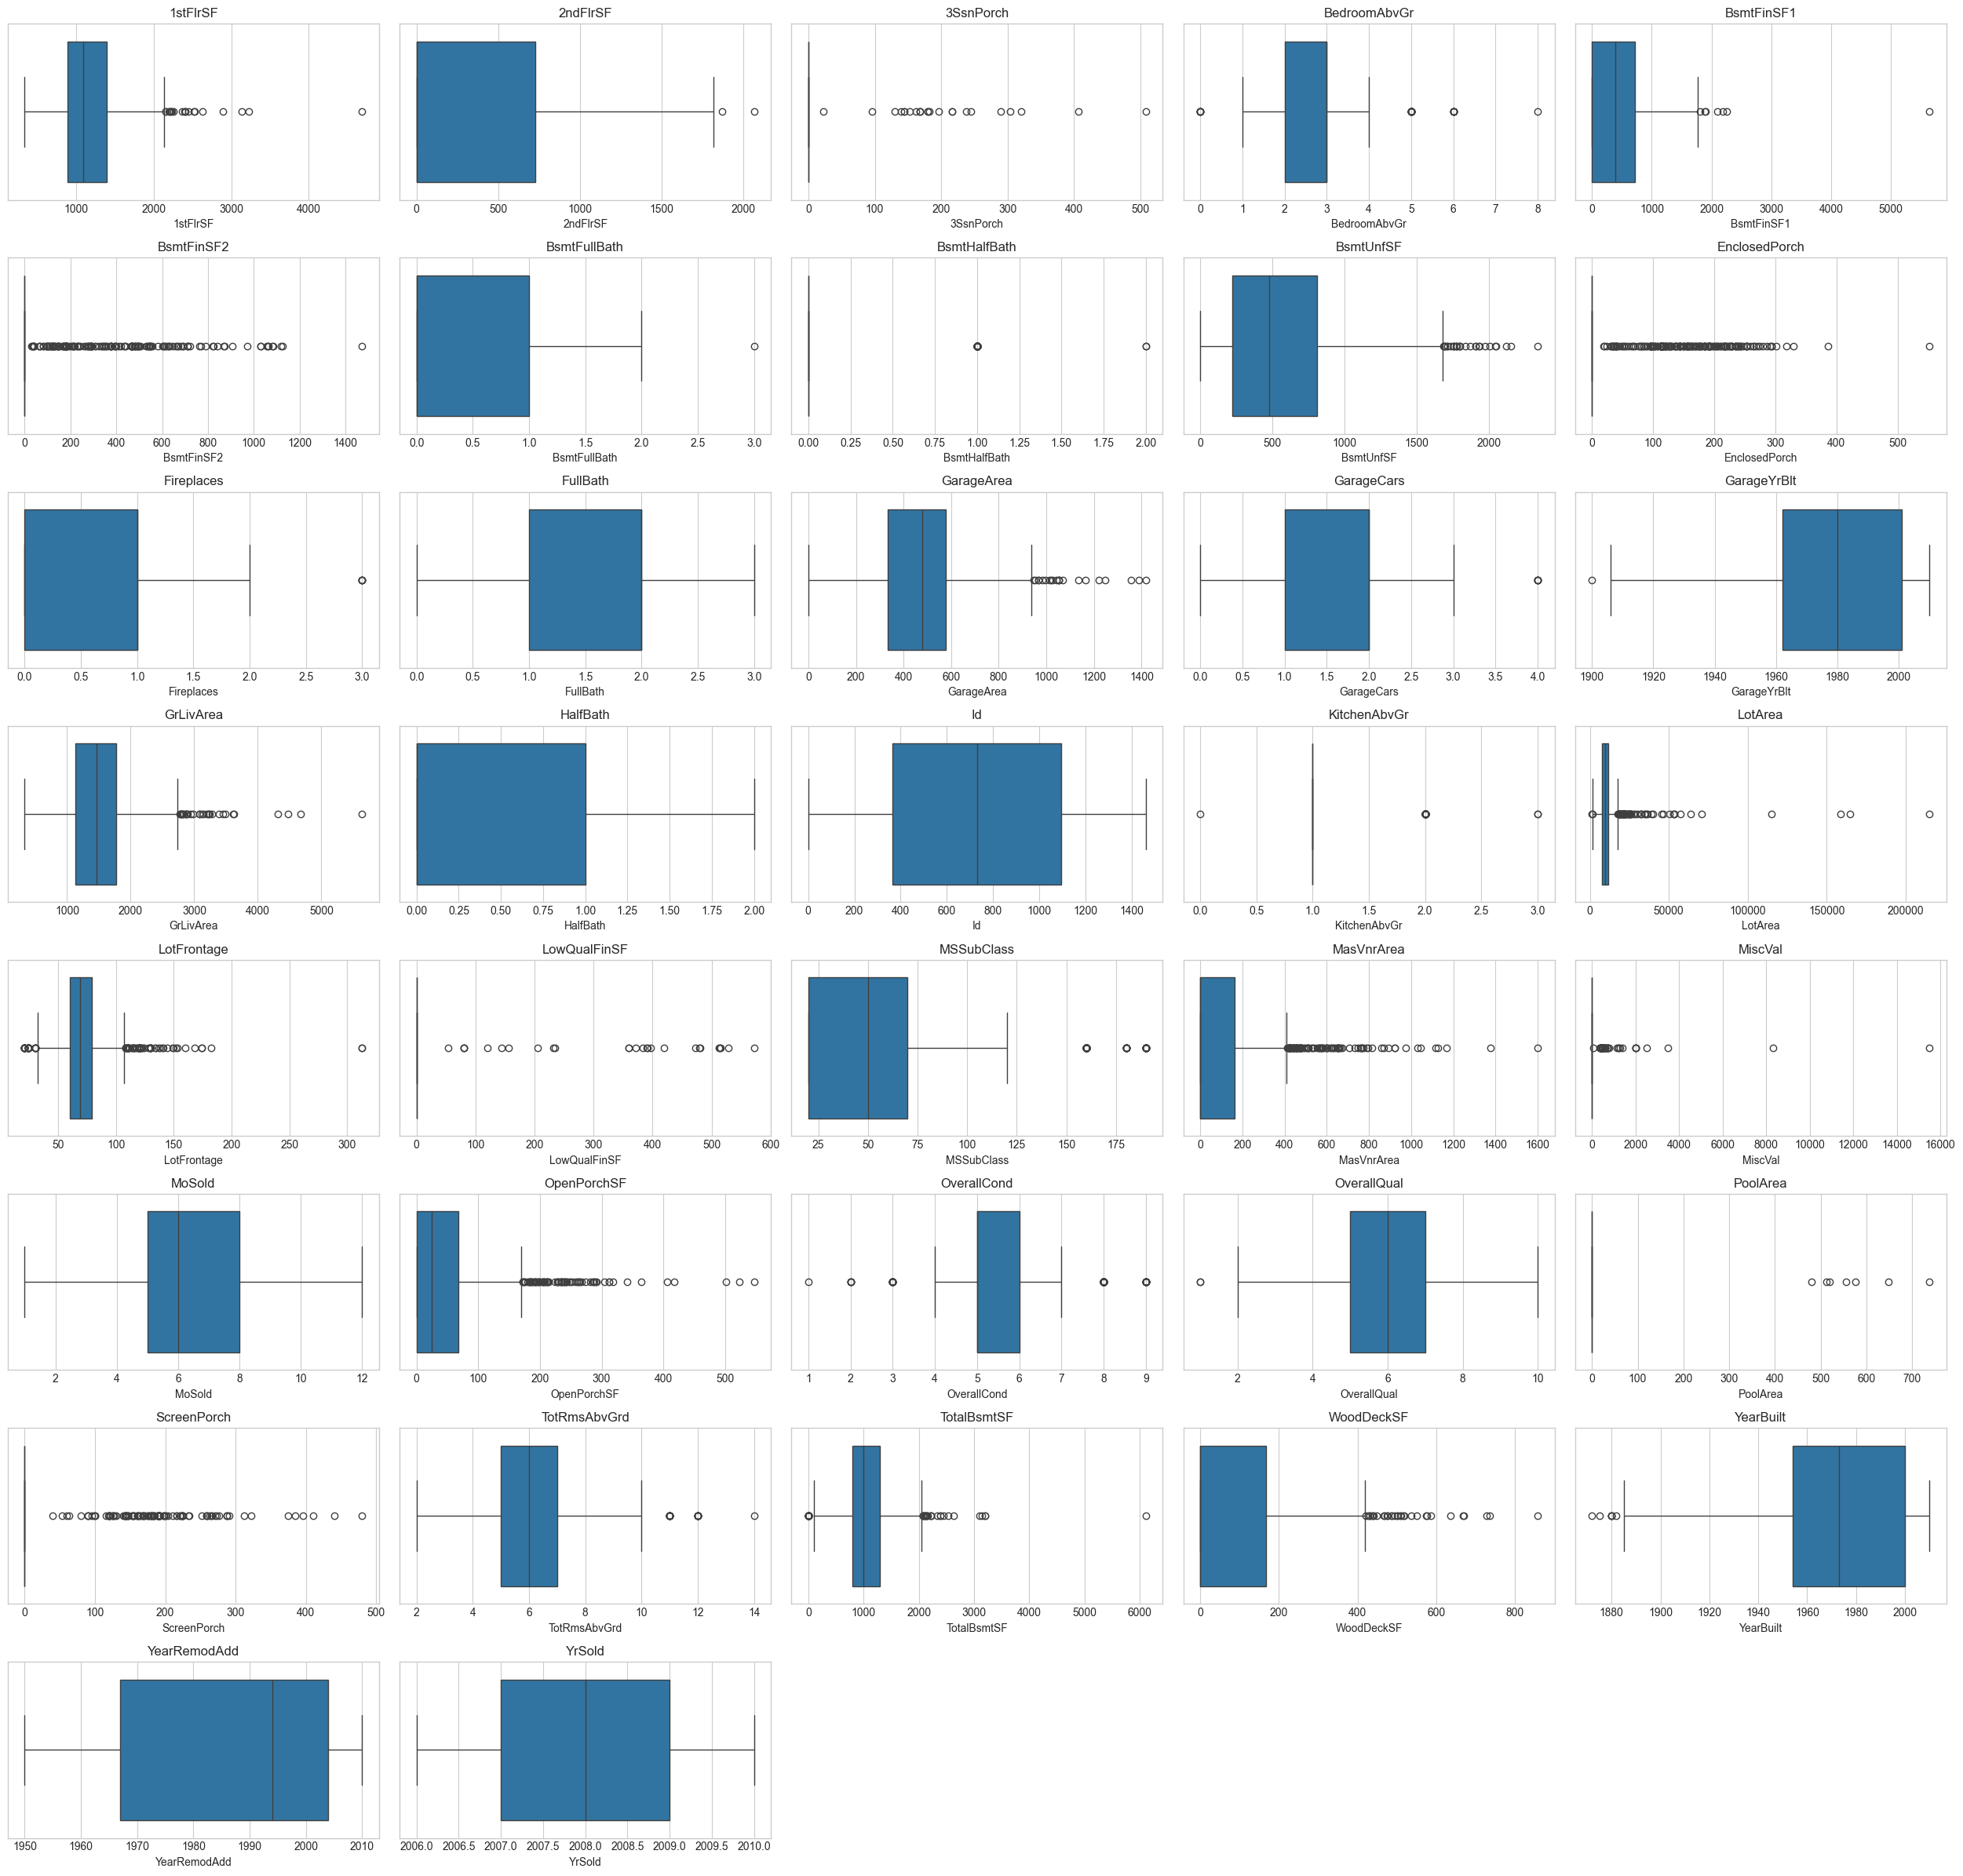

In [223]:
def plot_outliers(df, columns=None, columns_per_row=5, figsize_per_plot=(5, 3)):
    """
    Visualize potential outliers using boxplots.
    """
    if columns is None:
        columns = numerical_features

    columns = [col for col in columns if col in df.columns]

    if not columns:
        print("No numerical features available.")
        return

    rows = (len(columns) + columns_per_row - 1) // columns_per_row

    fig, axes = plt.subplots(
        rows,
        columns_per_row,
        figsize=(
            figsize_per_plot[0] * columns_per_row,
            figsize_per_plot[1] * rows
        ),
        squeeze=False
    )

    for ax, column in zip(axes.flat, columns):
        sns.boxplot(x=df[column], ax=ax)
        ax.set_title(column)

    for ax in axes.flat[len(columns):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()


plot_outliers(df_clean)

In [187]:
def handle_outliers_iqr(df, columns=None, multiplier=1.5):
    """
    Remove rows containing IQR-based outliers in selected numerical columns.
    Note: This removes entire rows and can remove legitimate values. 
    For house-price prediction, inspect outliers before removing them, especially in the target column SalePrice.
    """
    df = df.copy()

    if columns is None:
        columns = df.select_dtypes(include="number").columns.tolist()

    for column in columns:
        q1 = df[column].quantile(0.25)
        q3 = df[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - multiplier * iqr
        upper_bound = q3 + multiplier * iqr

        df = df[
            df[column].between(lower_bound, upper_bound) |
            df[column].isna()
        ]

    return df

df_clean_outliers = handle_outliers_iqr(df_clean)
print("Outlier Summary After Handling Outliers:")
display(outlier_summary(df_clean_outliers))

print("Shape after handling outliers:", df_clean_outliers.shape)

# Since the target variable is crucial for regression, let's inspect the outliers in the target column 'SalePrice' before deciding to remove them.

Outlier Summary After Handling Outliers:


,column,outlier_count,outlier_percentage
0,GarageCars,195,35.583942
1,GarageArea,38,6.934307
2,LotFrontage,30,5.474453
3,LotArea,20,3.649635
4,MasVnrArea,8,1.459854
5,OpenPorchSF,5,0.912409
6,SalePrice,4,0.729927
7,GrLivArea,4,0.729927
8,GarageYrBlt,1,0.182482
9,MSSubClass,0,0.000000


Shape after handling outliers: (548, 81)


In [188]:
def target_summary(df, target):
    """
    Print validation details for a regression target.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    print(f"Target: {target}")
    print(f"Data type: {df[target].dtype}")
    print(f"Missing values: {df[target].isna().sum()}")
    print(f"Unique values: {df[target].nunique()}")
    print(f"Standard deviation: {df[target].std()}")

    print("\nStatistics:")
    display(df[target].describe())

print("Target Summary: \n")
display(target_summary(df_clean, TARGET_COLUMN))

Target Summary: 

Target: SalePrice
Data type: int64
Missing values: 0
Unique values: 663
Standard deviation: 79442.50288288662

Statistics:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

None

In [222]:
def handle_target(df, target=TARGET_COLUMN):
    """
    Validate and clean the regression target.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    df = df.copy()

    # Remove rows with missing target values
    df = df.dropna(subset=[target])

    # Ensure target is numeric
    df[target] = pd.to_numeric(df[target], errors="coerce")

    # Remove rows that became missing after conversion
    df = df.dropna(subset=[target])

    # Reject invalid negative target values
    df = df[df[target] >= 0]

    return df


df_clean = handle_target(df_clean, target=TARGET_COLUMN)
print("Target Summary After Handling Target: \n")
display(target_summary(df_clean, TARGET_COLUMN))
print("\nShape after handling target:", df_clean.shape)

Target Summary After Handling Target: 

Target: SalePrice
Data type: int64
Missing values: 0
Unique values: 663
Standard deviation: 79442.50288288662

Statistics:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

None


Shape after handling target: (1460, 81)


## Exploratory Data Analysis

### Target Variable Distribution

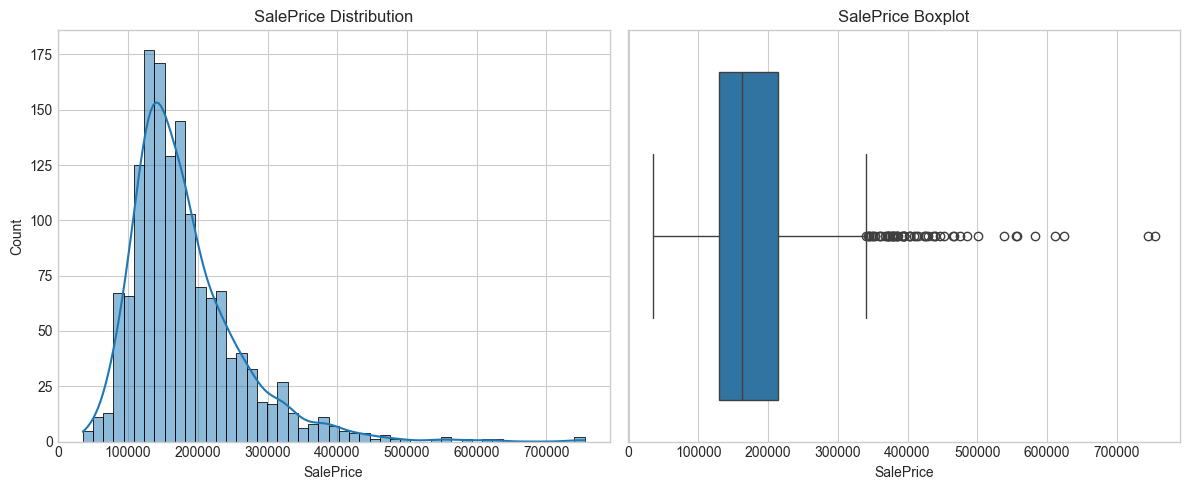

In [161]:
def plot_target_distribution(df, target=TARGET_COLUMN, figsize=(12, 5)):
    """
    Plot the target variable's distribution and boxplot.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    fig, axes = plt.subplots(1, 2, figsize=figsize)

    sns.histplot(df[target].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f"{target} Distribution")
    axes[0].set_xlabel(target)

    sns.boxplot(x=df[target], ax=axes[1])
    axes[1].set_title(f"{target} Boxplot")
    axes[1].set_xlabel(target)

    plt.tight_layout()
    plt.show()

plot_target_distribution(df_clean, target=TARGET_COLUMN)

In [162]:
def summarize_target_distribution(df, target=TARGET_COLUMN):
    """
    Display descriptive statistics and skewness for the target.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    print(f"Target: {target}")
    print(f"Skewness: {df[target].skew():.3f}")
    print("\nDescriptive Statistics:")
    display(df[target].describe().to_frame())


summarize_target_distribution(df_clean, target=TARGET_COLUMN)

Target: SalePrice
Skewness: 1.883

Descriptive Statistics:


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


### Numerical Feature Distributions

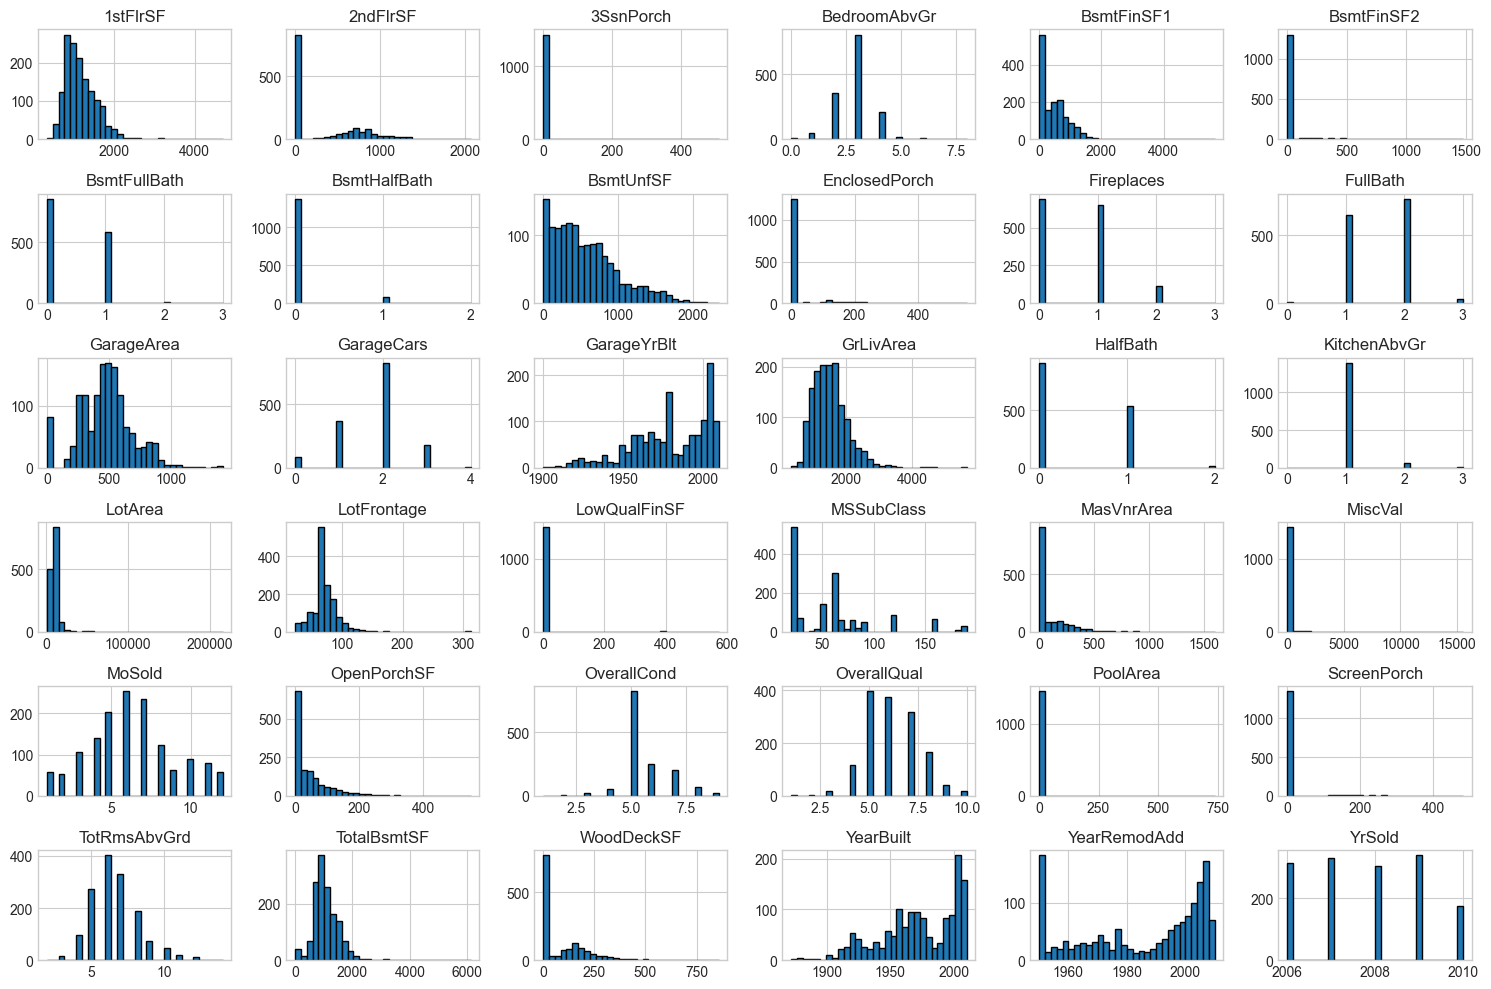

In [198]:
def plot_numerical_distributions(df, exclude=None, columns_per_row=3, figsize=(15, 10)):
    """
    Plot histograms and KDE curves for numerical features.
    """
    numeric_df = df[numerical_features]
    exclude = exclude or []

    numeric_df = numeric_df.drop(
        columns=exclude, errors="ignore"
    )

    if numeric_df.empty:
        print("No numerical features available.")
        return

    numeric_df.hist(
        bins=30,
        figsize=figsize,
        layout=None,
        edgecolor="black"
    )

    plt.tight_layout()
    plt.show()


plot_numerical_distributions(df_clean, exclude=[TARGET_COLUMN, ID_COLUMN])

In [197]:
def summarize_numerical_distributions(df, exclude=None):
    """
    Display descriptive statistics and skewness for numerical features.
    """
    numeric_df = df[numerical_features]
    exclude = exclude or []

    numeric_df = numeric_df.drop(
        columns=exclude, errors="ignore"
    )

    summary = numeric_df.describe().T
    summary["skewness"] = numeric_df.skew()
    summary["missing_count"] = numeric_df.isna().sum()

    print("Numerical Features Summary: \n")
    display(summary)


summarize_numerical_distributions(df_clean, exclude=[TARGET_COLUMN, ID_COLUMN])

Numerical Features Summary: 



,count,mean,std,min,25%,50%,75%,max,skewness,missing_count
1stFlrSF,1460.0,1162.626712,386.587738,334.0,882.00,1087.0,1391.25,4692.0,1.376757,0
2ndFlrSF,1460.0,346.992466,436.528436,0.0,0.00,0.0,728.00,2065.0,0.813030,0
3SsnPorch,1460.0,3.409589,29.317331,0.0,0.00,0.0,0.00,508.0,10.304342,0
BedroomAbvGr,1460.0,2.866438,0.815778,0.0,2.00,3.0,3.00,8.0,0.211790,0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0,1.685503,0
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0,4.255261,0
BsmtFullBath,1460.0,0.425342,0.518911,0.0,0.00,0.0,1.00,3.0,0.596067,0
BsmtHalfBath,1460.0,0.057534,0.238753,0.0,0.00,0.0,0.00,2.0,4.103403,0
BsmtUnfSF,1460.0,567.240411,441.866955,0.0,223.00,477.5,808.00,2336.0,0.920268,0
EnclosedPorch,1460.0,21.954110,61.119149,0.0,0.00,0.0,0.00,552.0,3.089872,0


### Categorical Feature Distributions

Categorical Distributions: 



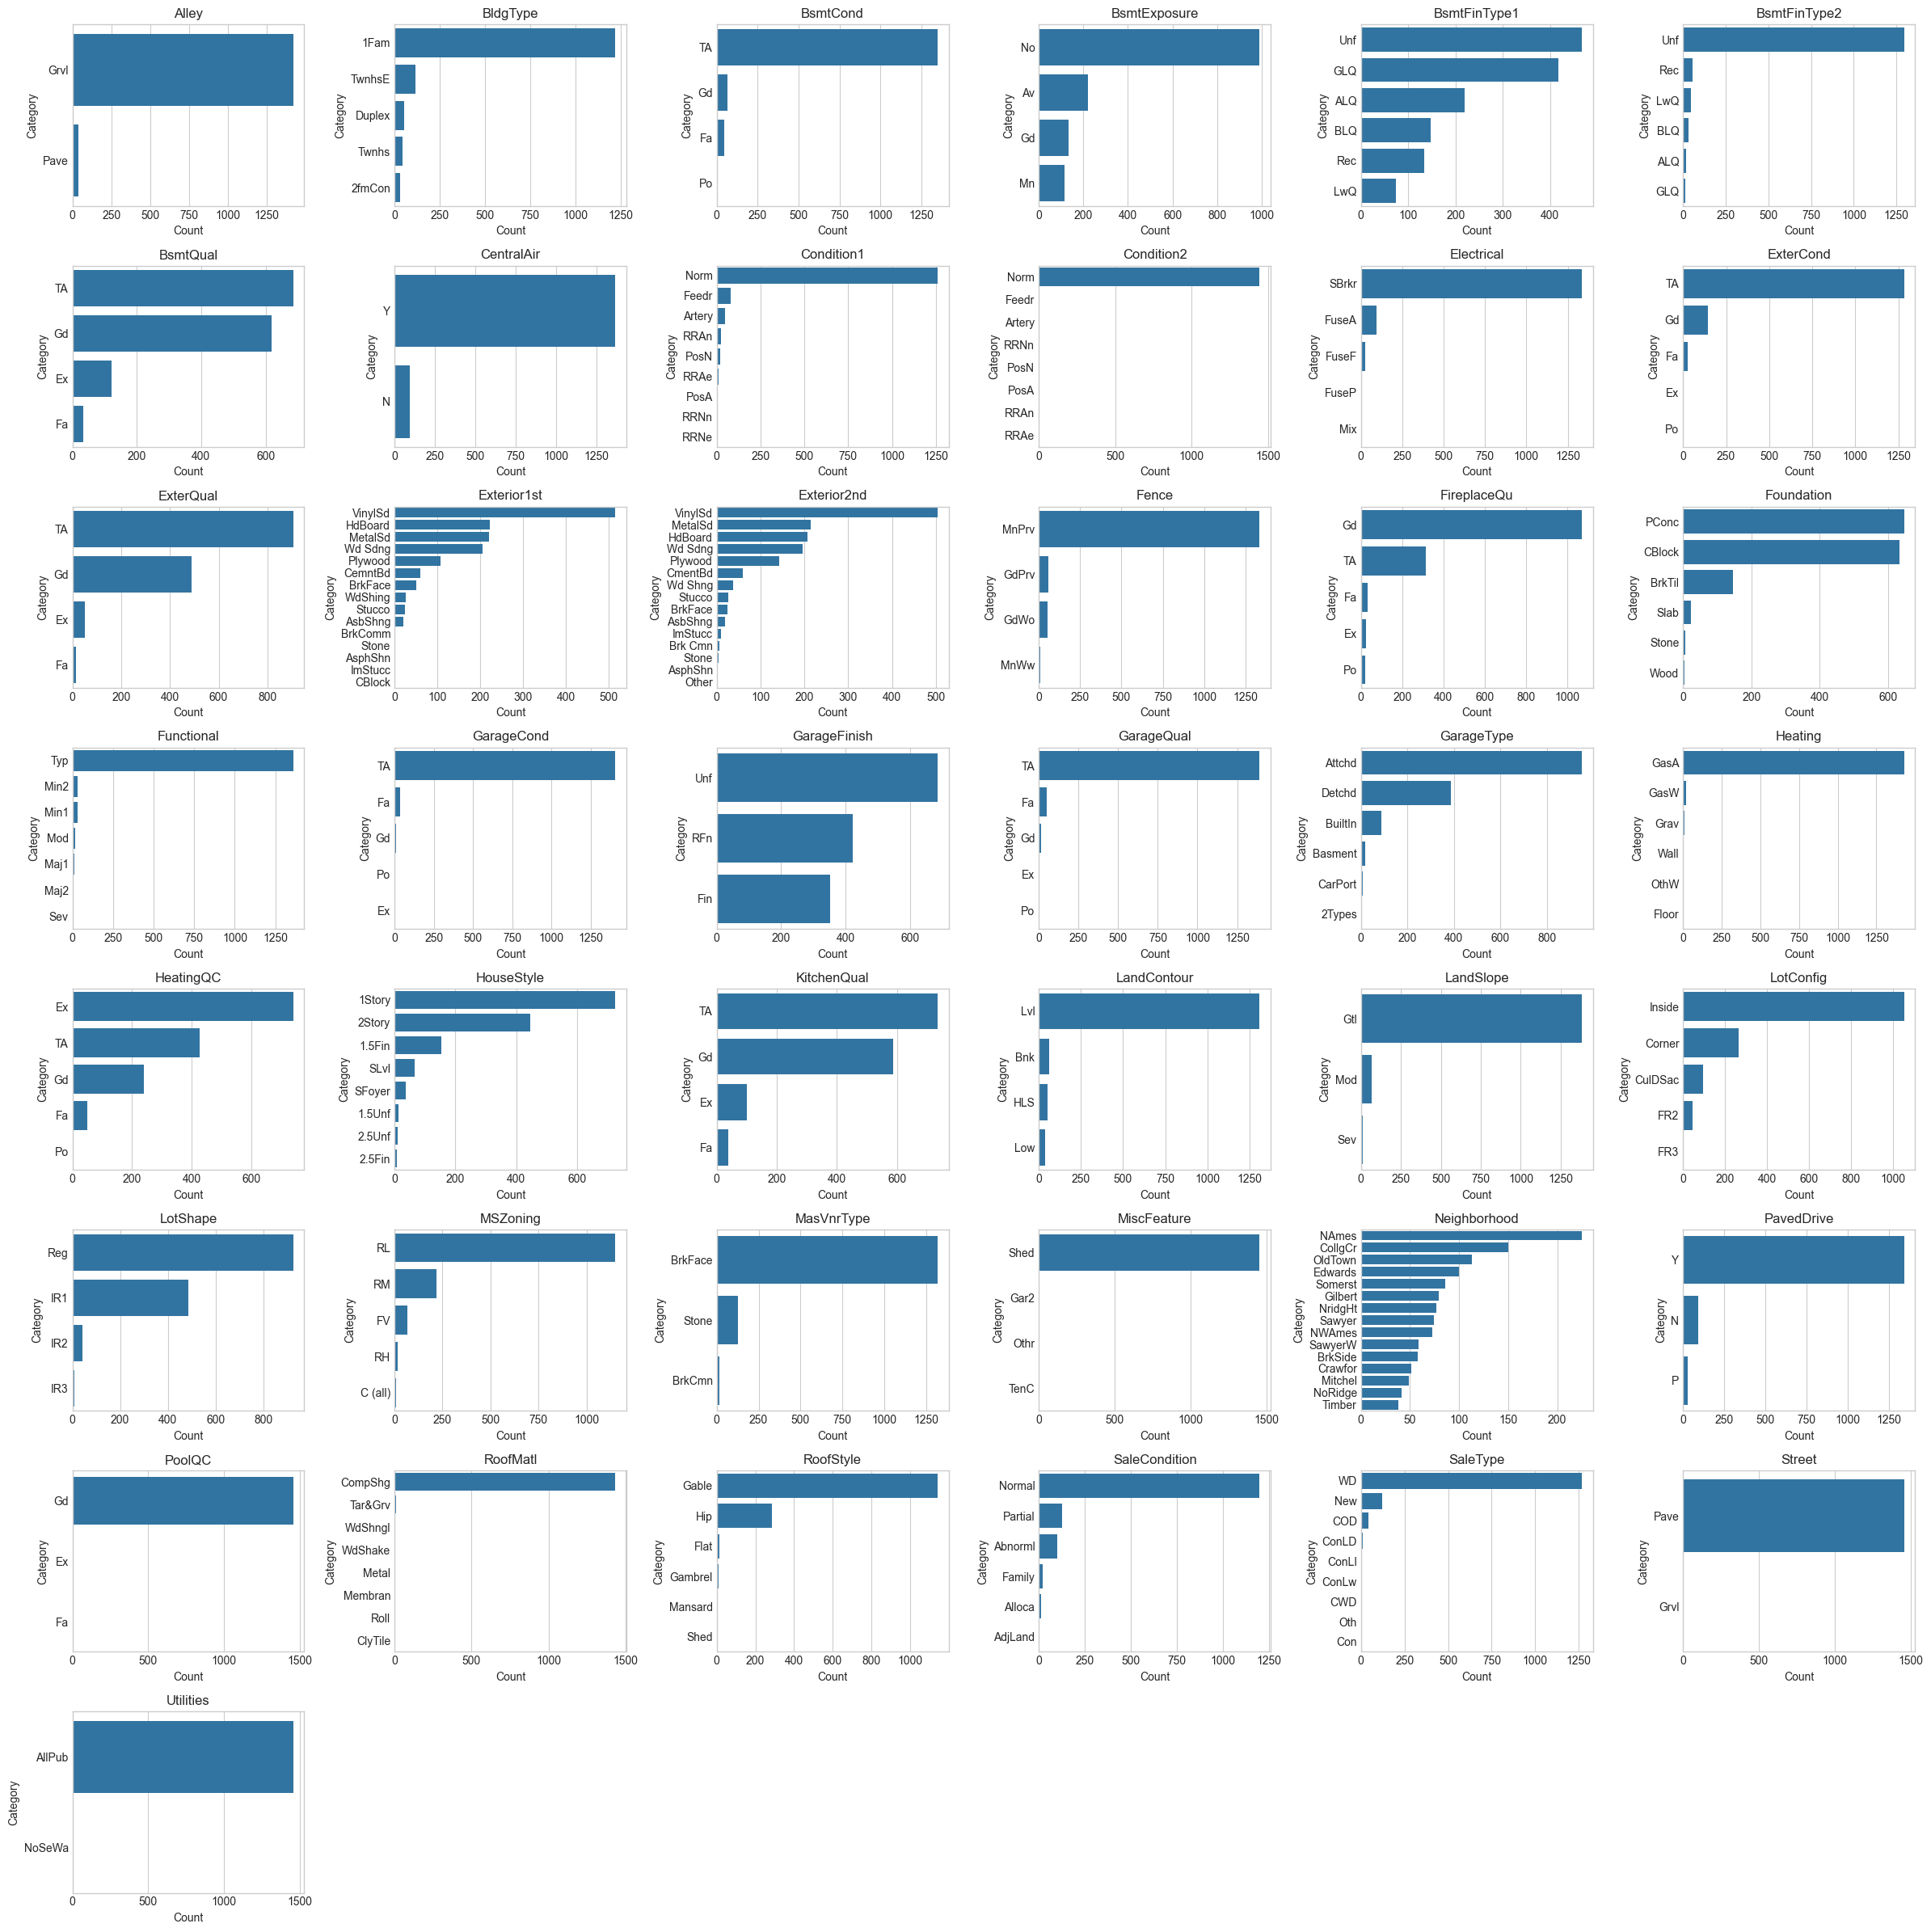

In [204]:
def plot_categorical_distributions(
    df,
    columns=None,
    max_categories=15,
    columns_per_row=6,
    figsize_per_plot=(4, 3)
):
    """
    Plot categorical feature distributions using subplots.
    """
    if columns is None:
        columns = categorical_features

    if not columns:
        print("No categorical features available.")
        return

    n_features = len(columns)
    rows = (n_features + columns_per_row - 1) // columns_per_row

    fig, axes = plt.subplots(
        rows,
        columns_per_row,
        figsize=(
            figsize_per_plot[0] * columns_per_row,
            figsize_per_plot[1] * rows
        ),
        squeeze=False
    )

    for ax, column in zip(axes.flat, columns):
        counts = df[column].value_counts(dropna=False).head(max_categories)

        sns.barplot(
            x=counts.values,
            y=counts.index.astype(str),
            ax=ax
        )
        ax.set_title(column)
        ax.set_xlabel("Count")
        ax.set_ylabel("Category")

    for ax in axes.flat[n_features:]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

print("Categorical Distributions: \n")
plot_categorical_distributions(df_clean)


In [205]:
def summarize_categorical_distributions(df, columns=None):
    """
    Return one table of category counts and percentages.
    """
    if columns is None:
        columns = categorical_features

    summary = []

    for column in columns:
        counts = df[column].value_counts(dropna=False)

        for category, count in counts.items():
            summary.append({
                "feature": column,
                "category": category,
                "count": count,
                "percentage": round(count / len(df) * 100, 2)
            })

    display(pd.DataFrame(summary))


print("Categorical Distributions Summary: \n")
summarize_categorical_distributions(df_clean)

Categorical Distributions Summary: 



,feature,category,count,percentage
0,Alley,Grvl,1419,97.19
1,Alley,Pave,41,2.81
2,BldgType,1Fam,1220,83.56
3,BldgType,TwnhsE,114,7.81
4,BldgType,Duplex,52,3.56
...,...,...,...,...
246,SaleType,Con,2,0.14
247,Street,Pave,1454,99.59
248,Street,Grvl,6,0.41
249,Utilities,AllPub,1459,99.93


### Feature–Target Relationships

Feature-Target Relationships: 

Numerical Features vs Target: 
['1stFlrSF', '2ndFlrSF', '3SsnPorch', 'BedroomAbvGr', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtFullBath', 'BsmtHalfBath', 'BsmtUnfSF', 'EnclosedPorch', 'Fireplaces', 'FullBath', 'GarageArea', 'GarageCars', 'GarageYrBlt', 'GrLivArea', 'HalfBath', 'Id', 'KitchenAbvGr', 'LotArea', 'LotFrontage', 'LowQualFinSF', 'MSSubClass', 'MasVnrArea', 'MiscVal', 'MoSold', 'OpenPorchSF', 'OverallCond', 'OverallQual', 'PoolArea', 'ScreenPorch', 'TotRmsAbvGrd', 'TotalBsmtSF', 'WoodDeckSF', 'YearBuilt', 'YearRemodAdd', 'YrSold'] 



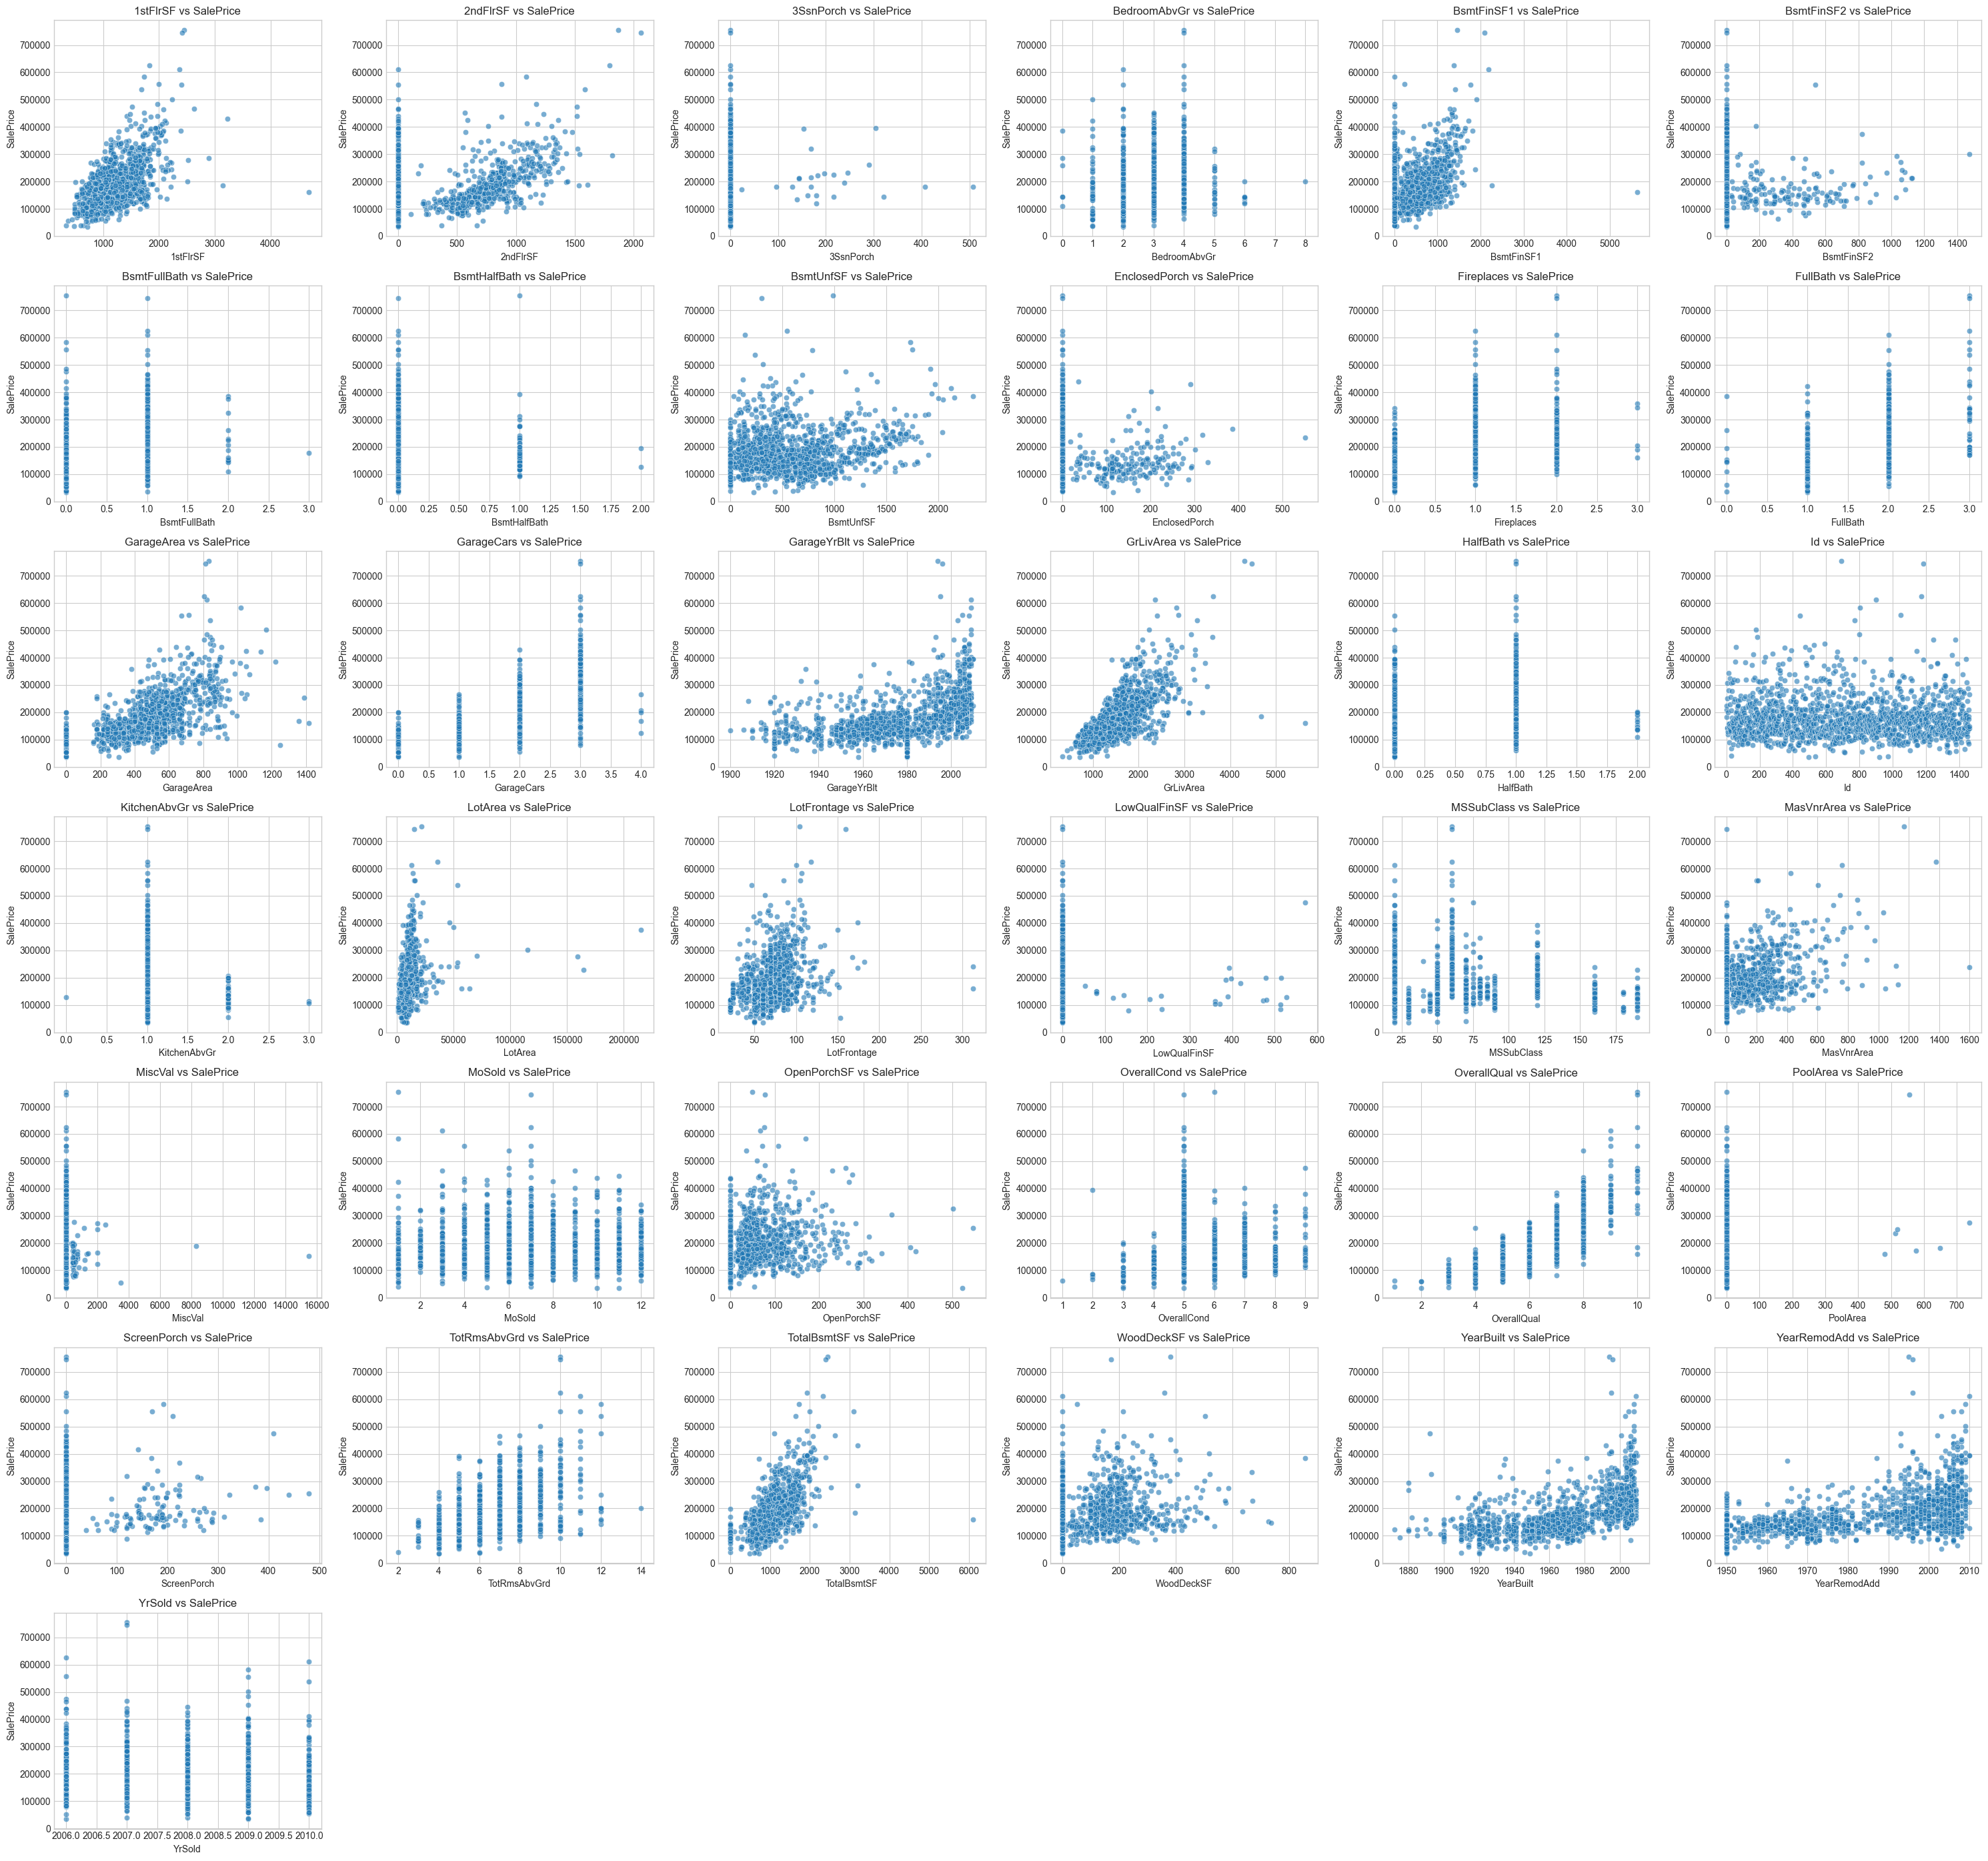

Categorical Features vs Target: 
['Alley', 'BldgType', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'BsmtQual', 'CentralAir', 'Condition1', 'Condition2', 'Electrical', 'ExterCond', 'ExterQual', 'Exterior1st', 'Exterior2nd', 'Fence', 'FireplaceQu', 'Foundation', 'Functional', 'GarageCond', 'GarageFinish', 'GarageQual', 'GarageType', 'Heating', 'HeatingQC', 'HouseStyle', 'KitchenQual', 'LandContour', 'LandSlope', 'LotConfig', 'LotShape', 'MSZoning', 'MasVnrType', 'MiscFeature', 'Neighborhood', 'PavedDrive', 'PoolQC', 'RoofMatl', 'RoofStyle', 'SaleCondition', 'SaleType', 'Street', 'Utilities'] 



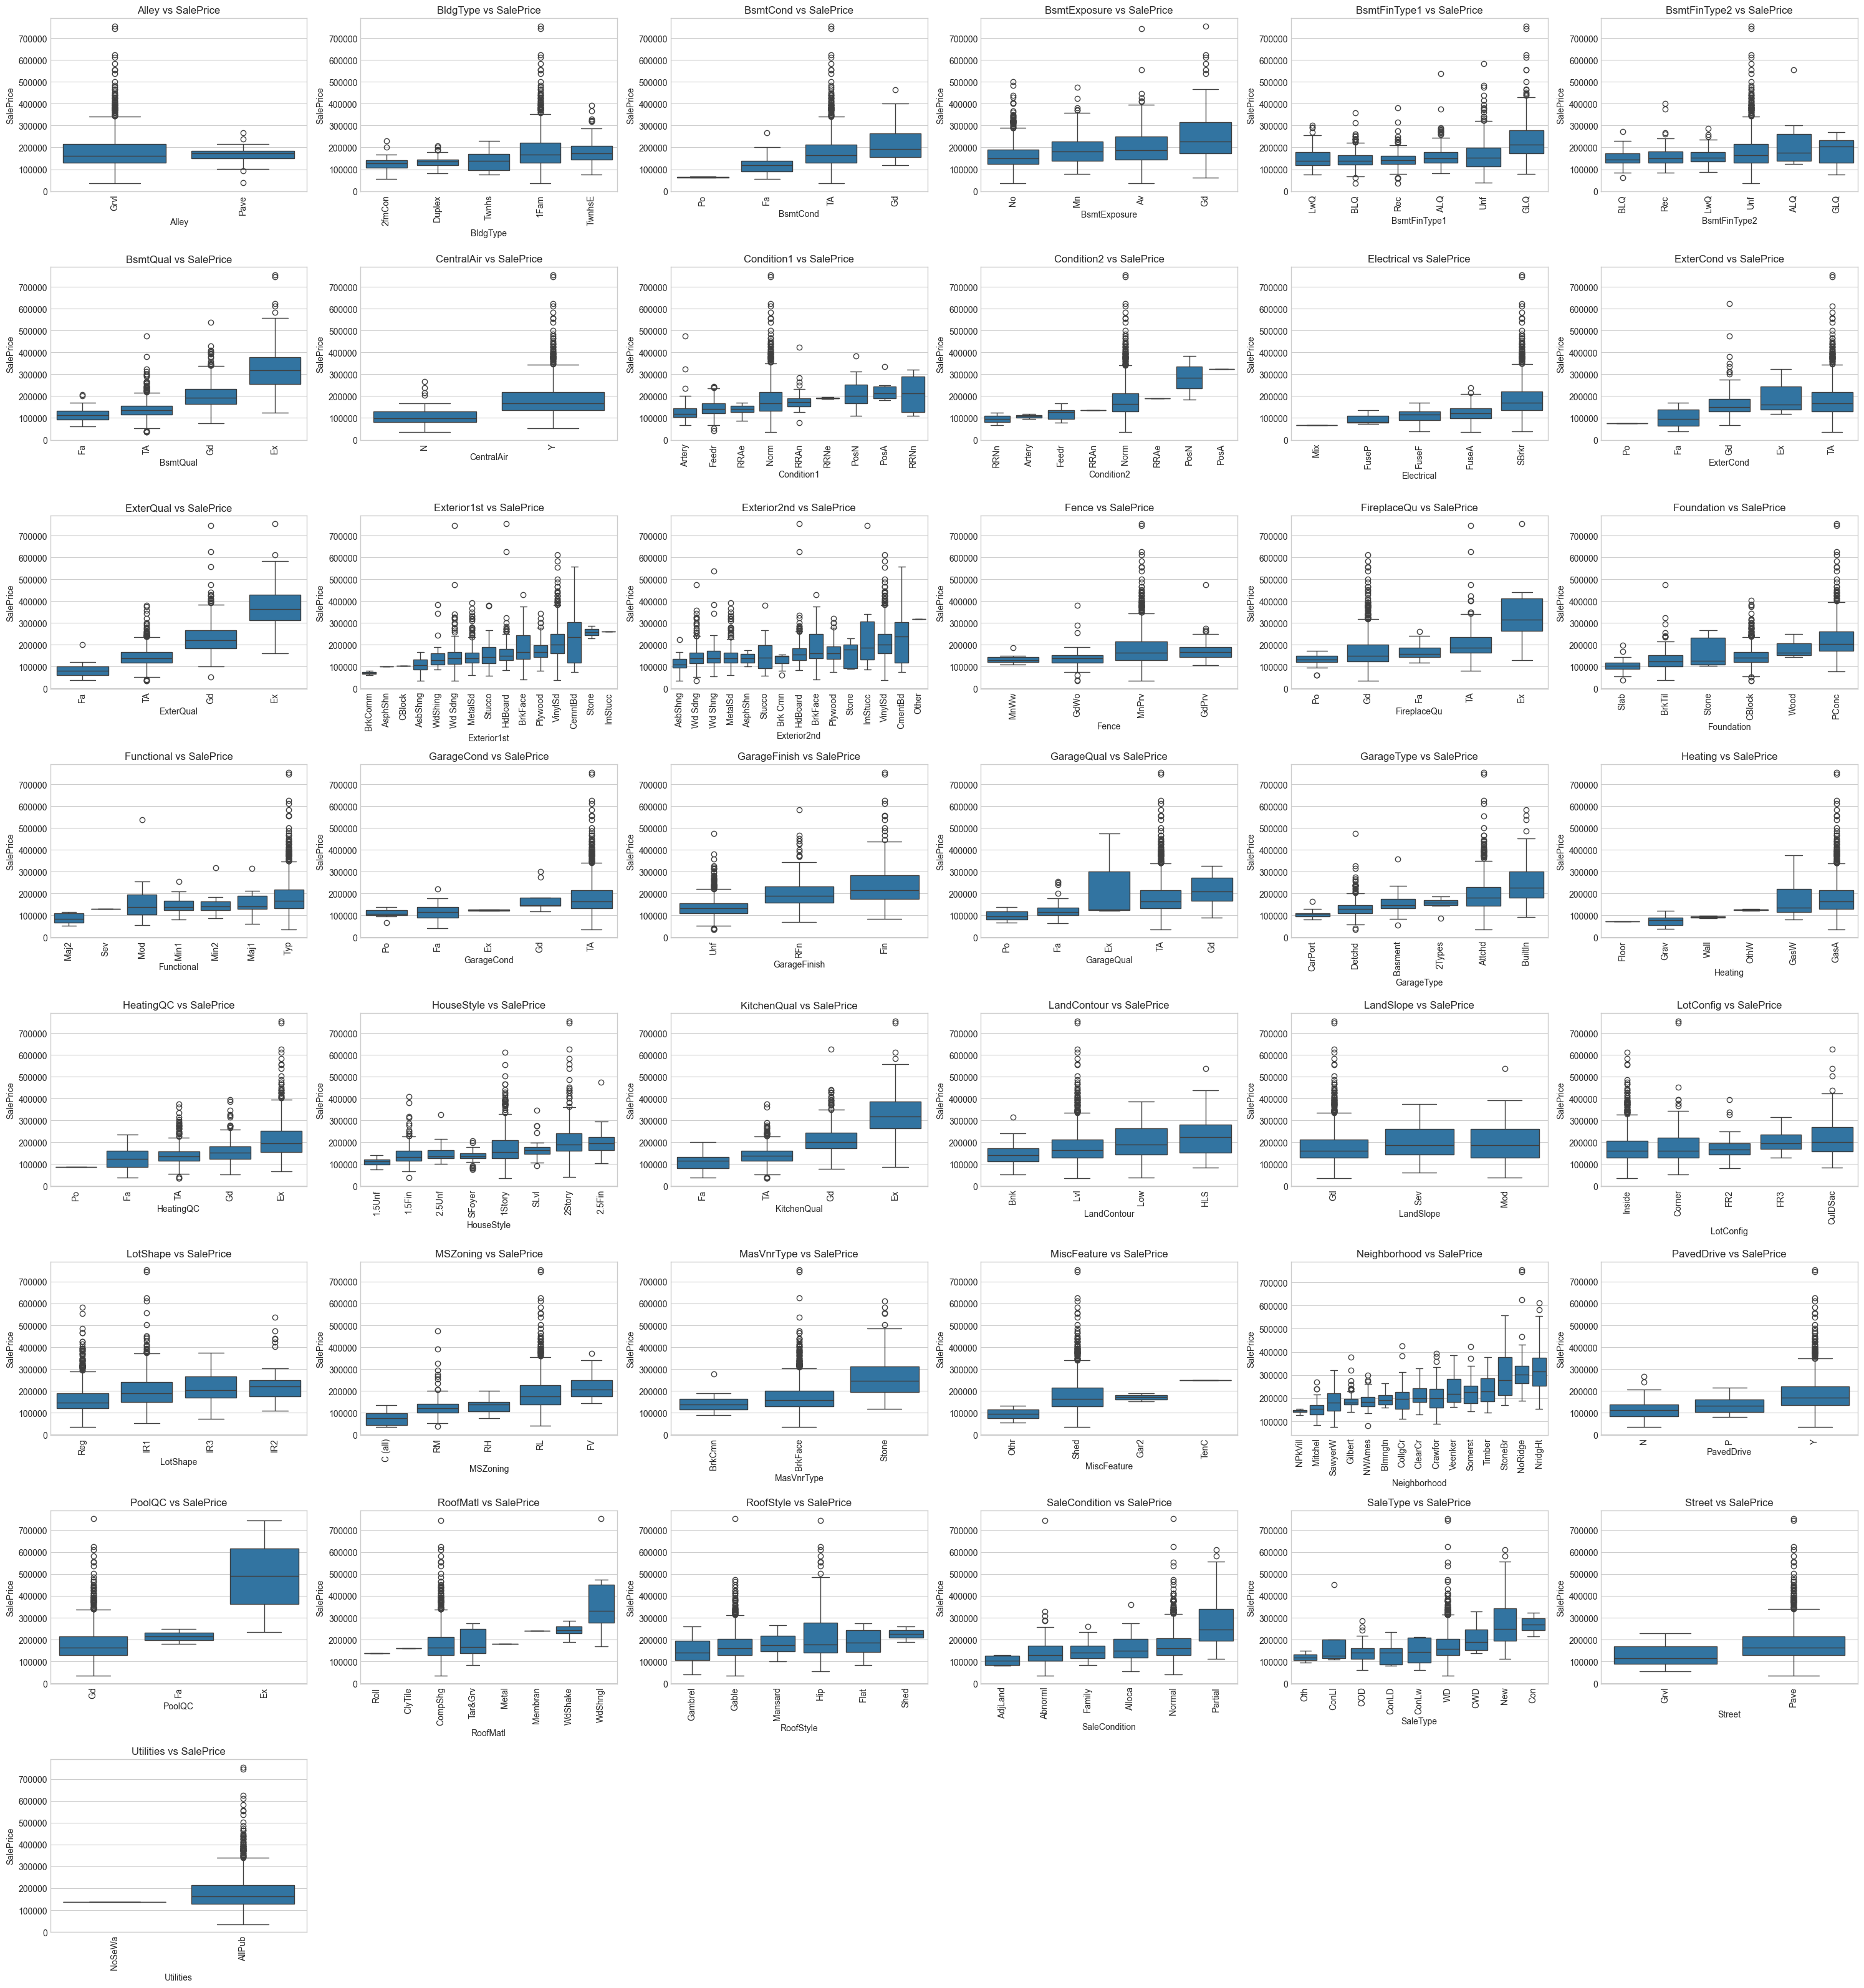

In [211]:
def plot_feature_target_relationships(
    df,
    target=TARGET_COLUMN,
    numerical_columns=None,
    categorical_columns=None,
    columns_per_row=6,
    figsize_per_plot=(5, 4),
    max_categories=15
):
    """
    Plot numerical and categorical feature relationships with the target.
    """
    if numerical_columns is None:
        numerical_columns = numerical_features

    if categorical_columns is None:
        categorical_columns = categorical_features

    numerical_columns = [
        col for col in numerical_columns
        if col != target and col in df.columns
    ]
    categorical_columns = [
        col for col in categorical_columns
        if col != target and col in df.columns
    ]

    print(f"Numerical Features vs Target: \n{numerical_columns} \n")

    # Numerical features vs target
    if numerical_columns:
        rows = (len(numerical_columns) + columns_per_row - 1) // columns_per_row

        fig, axes = plt.subplots(
            rows, columns_per_row,
            figsize=(
                figsize_per_plot[0] * columns_per_row,
                figsize_per_plot[1] * rows
            ),
            squeeze=False
        )

        for ax, column in zip(axes.flat, numerical_columns):
            sns.scatterplot(data=df, x=column, y=target, alpha=0.6, ax=ax)
            ax.set_title(f"{column} vs {target}")

        for ax in axes.flat[len(numerical_columns):]:
            ax.set_visible(False)

        plt.tight_layout()
        plt.show()

    print(f"Categorical Features vs Target: \n{categorical_columns} \n")

    # Categorical features vs target
    if categorical_columns:
        rows = (len(categorical_columns) + columns_per_row - 1) // columns_per_row

        fig, axes = plt.subplots(
            rows, columns_per_row,
            figsize=(
                figsize_per_plot[0] * columns_per_row,
                figsize_per_plot[1] * rows
            ),
            squeeze=False
        )

        for ax, column in zip(axes.flat, categorical_columns):
            order = (
                df.groupby(column, observed=True)[target]
                .median()
                .sort_values()
                .tail(max_categories)
                .index
            )

            sns.boxplot(
                data=df[df[column].isin(order)],
                x=column,
                y=target,
                order=order,
                ax=ax
            )
            ax.set_title(f"{column} vs {target}")
            ax.tick_params(axis="x", rotation=90)

        for ax in axes.flat[len(categorical_columns):]:
            ax.set_visible(False)

        plt.tight_layout()
        plt.show()

print("Feature-Target Relationships: \n")
plot_feature_target_relationships(df_clean)

### Correlation Analysis

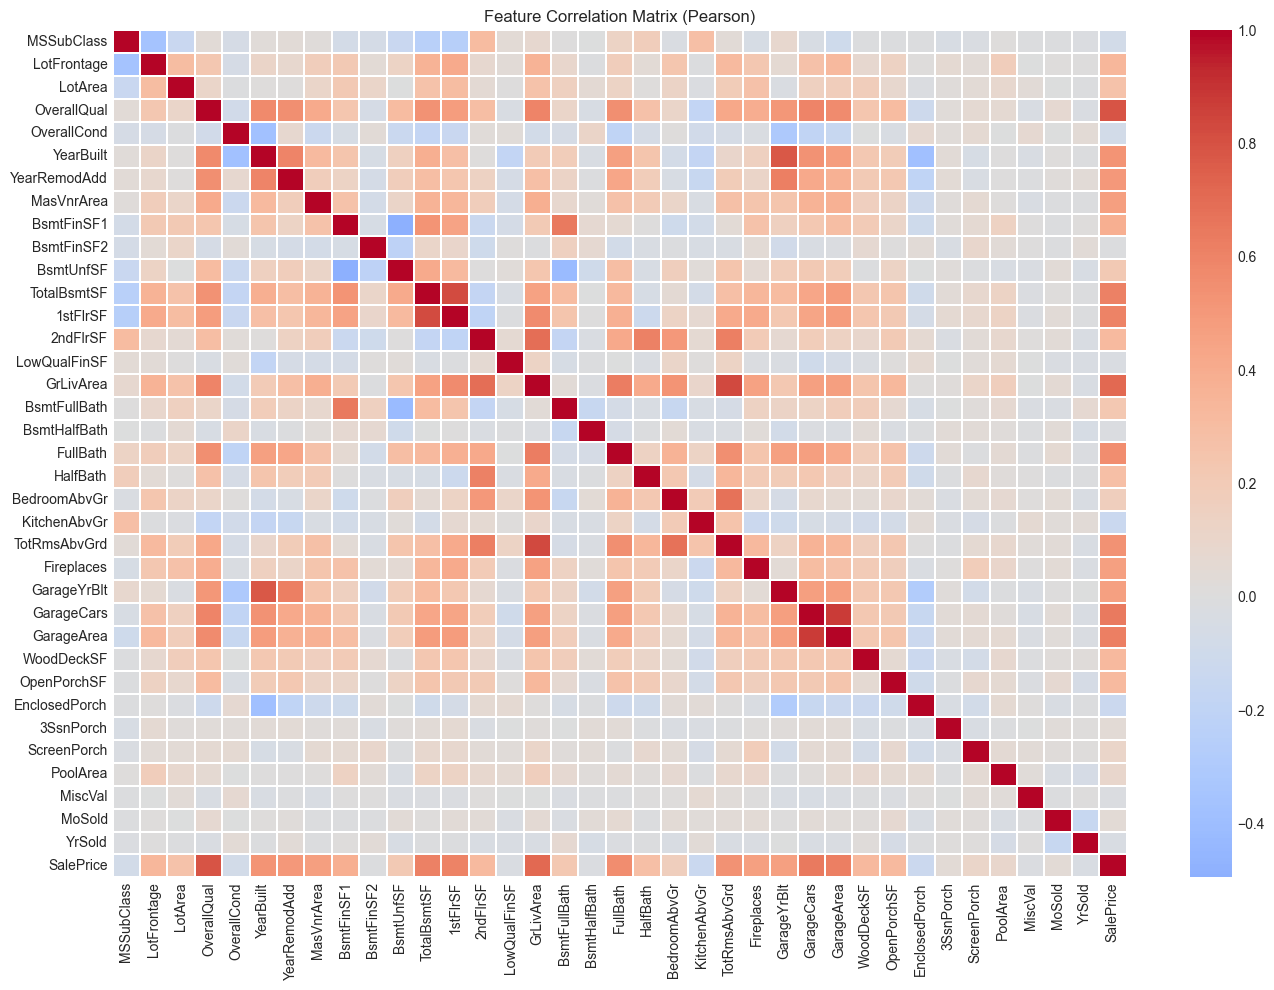

Top 20 features correlated with SalePrice:


,correlation_with_target
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


In [214]:
def correlation_analysis(
    df,
    target=TARGET_COLUMN,
    method="pearson",
    top_n=20,
    figsize=(14, 10)
):
    """
    Display a correlation heatmap and features most correlated with the target.
    """
    numeric_df = df.select_dtypes(include="number").drop(
        columns=["Id"], errors="ignore"
    )

    correlations = numeric_df.corr(method=method)

    # Correlation heatmap
    plt.figure(figsize=figsize)
    sns.heatmap(
        correlations,
        cmap="coolwarm",
        center=0,
        linewidths=0.3
    )
    plt.title(f"Feature Correlation Matrix ({method.title()})")
    plt.tight_layout()
    plt.show()

    # Features most correlated with the target
    if target in correlations.columns:
        target_corr = (
            correlations[target]
            .drop(target)
            .dropna()
            .sort_values(key=abs, ascending=False)
            .head(top_n)
            .to_frame("correlation_with_target")
        )

        print(f"Top {top_n} features correlated with {target}:")
        display(target_corr)


correlation_analysis(df_clean)

### Outlier Investigation

In [220]:
print("Outlier Summary:")  
display(outlier_summary(df_clean))

Outlier Summary:


,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
9,EnclosedPorch,0.000,0.000,208,14.25
5,BsmtFinSF2,0.000,0.000,167,11.44
27,OverallCond,3.500,7.500,125,8.56
30,ScreenPorch,0.000,0.000,116,7.95
20,LotFrontage,31.500,107.500,106,7.26
22,MSSubClass,-55.000,145.000,103,7.05
23,MasVnrArea,-246.375,410.625,98,6.71
7,BsmtHalfBath,0.000,0.000,82,5.62
26,OpenPorchSF,-102.000,170.000,77,5.27
19,LotArea,1481.500,17673.500,69,4.73


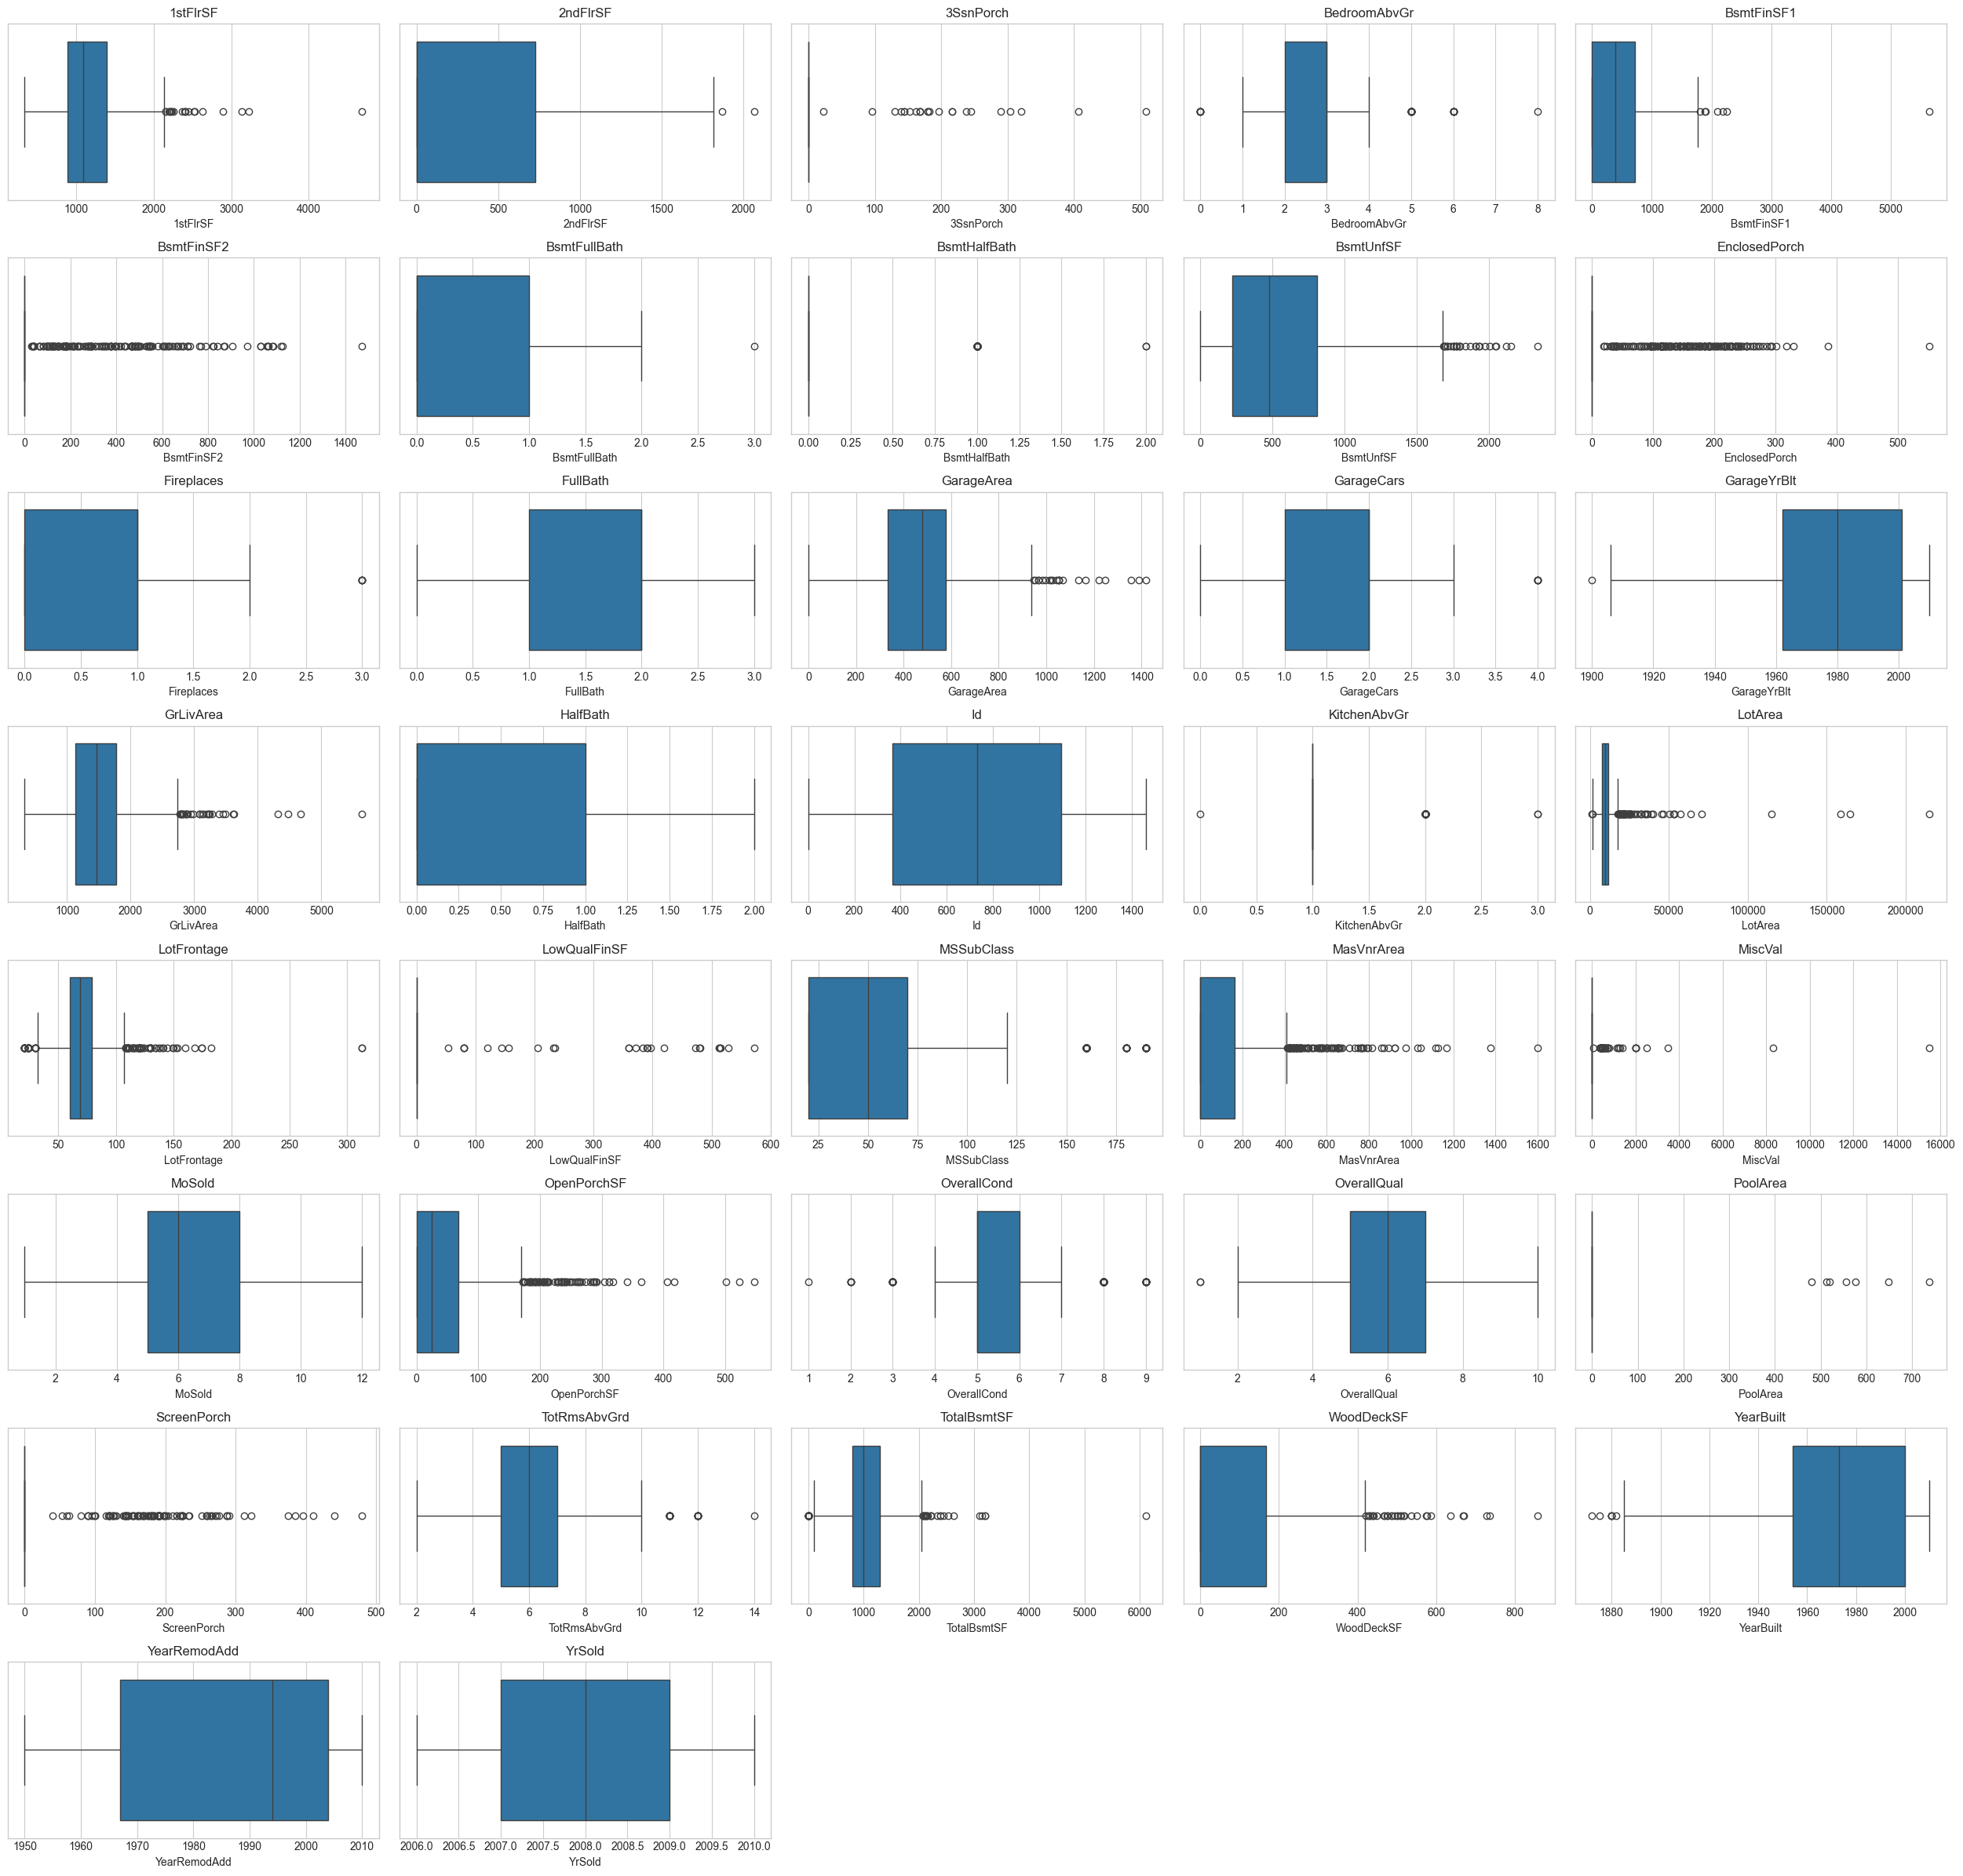

In [224]:
plot_outliers(df_clean)

### EDA Findings and Insights Documentation

In [231]:
eda_findings = pd.DataFrame([
    {
        "area": "Target Distribution",
        "finding": "SalePrice is right-skewed with high-priced outliers.",
        "insight": "Log transformation may improve the target distribution.",
        "action": "Evaluate log1p(SalePrice) during modeling."
    },
    {
        "area": "Numerical Distributions",
        "finding": "GrLivArea, LotArea, and some other features are right-skewed.",
        "insight": "Extreme values may influence certain models.",
        "action": "Investigate extreme values and consider transformations where appropriate."
    },
    {
        "area": "Categorical Distributions",
        "finding": "Some categories, such as PoolQC and MiscFeature, contain many missing values or rare categories.",
        "insight": "Missingness may indicate that a feature is absent, not that data is unknown.",
        "action": "Interpret missing values using the dataset documentation before imputing."
    },
    {
        "area": "Feature–Target Relationships",
        "finding": "OverallQual, GrLivArea, and GarageCars generally have strong positive relationships with SalePrice.",
        "insight": "Quality, living area, and garage capacity are potentially useful predictors.",
        "action": "Retain these features as modeling candidates."
    },
    {
        "area": "Correlation Analysis",
        "finding": "OverallQual, GrLivArea, GarageCars, and GarageArea are associated with SalePrice; GarageCars and GarageArea are also strongly correlated with each other.",
        "insight": "Some features provide overlapping information.",
        "action": "Check multicollinearity if using linear regression."
    },
    {
        "area": "Feature Importance Exploration",
        "finding": "OverallQual, GrLivArea, and other size and quality features are plausible important predictors.",
        "insight": "Property quality and size may contribute substantially to predictions.",
        "action": "Confirm feature importance using training data during modeling."
    }
])

pd.set_option("display.max_colwidth", 50)
pd.set_option("display.width", 1000)

display(eda_findings)

,area,finding,insight,action
0,Target Distribution,SalePrice is right-skewed with high-priced out...,Log transformation may improve the target dist...,Evaluate log1p(SalePrice) during modeling.
1,Numerical Distributions,"GrLivArea, LotArea, and some other features ar...",Extreme values may influence certain models.,Investigate extreme values and consider transf...
2,Categorical Distributions,"Some categories, such as PoolQC and MiscFeatur...",Missingness may indicate that a feature is abs...,Interpret missing values using the dataset doc...
3,Feature–Target Relationships,"OverallQual, GrLivArea, and GarageCars general...","Quality, living area, and garage capacity are ...",Retain these features as modeling candidates.
4,Correlation Analysis,"OverallQual, GrLivArea, GarageCars, and Garage...",Some features provide overlapping information.,Check multicollinearity if using linear regres...
5,Feature Importance Exploration,"OverallQual, GrLivArea, and other size and qua...",Property quality and size may contribute subst...,Confirm feature importance using training data...


## Feature Engineering Pipeline

In [230]:
df_processed = df_clean.copy()

### Feature Creation